In [1]:
import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

df = pd.read_csv("ache_ic50_clean.csv")
df = df[np.isfinite(df["pIC50"])].copy()
df = df.reset_index(drop=True)

In [2]:
def one_hot_with_unknown(value, choices):
    if value not in choices[:-1]:
        value = "Other"

    return [int(value == choice) for choice in choices]

In [3]:
from collections import Counter
from rdkit import Chem

element_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        for atom in mol.GetAtoms():
            element_counts[atom.GetSymbol()] += 1

print("Elements found:")
for element, count in element_counts.most_common():
    print(f"{element:>3s}: {count}")

Elements found:
  C: 149695
  O: 16710
  N: 16697
 Cl: 1733
  F: 1325
  S: 964
 Br: 681
  I: 109
  P: 53
 Se: 33
  B: 21
 Si: 6
  H: 4
 Na: 1


In [4]:
elements = [
    "C", "N", "O", "F", "P", "S",
    "Cl", "Br", "I",
    "B", "Si", "Se", "Na",
    "Other"
]

In [5]:
degree_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        for atom in mol.GetAtoms():
            degree_counts[atom.GetDegree()] += 1

print("Degrees found:")
for degree, count in sorted(degree_counts.items()):
    print(f"Degree {degree}: {count}")

Degrees found:
Degree 0: 1234
Degree 1: 24690
Degree 2: 104092
Degree 3: 55622
Degree 4: 2394


In [6]:
degrees = [0, 1, 2, 3, 4, "Other"]    

In [7]:
charge_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        for atom in mol.GetAtoms():
            charge_counts[atom.GetFormalCharge()] += 1

print("Formal charges found:")
for charge, count in sorted(charge_counts.items()):
    print(f"Charge {charge:+d}: {count}")

Formal charges found:
Charge -1: 1134
Charge +0: 185580
Charge +1: 1318


In [8]:
formal_charges = [-1, 0, 1, "Other"]    

In [9]:
#Hybridization
hybrid_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        for atom in mol.GetAtoms():
            hybrid_counts[str(atom.GetHybridization())] += 1

print("Hybridizations found:")
for hybrid, count in hybrid_counts.most_common():
    print(f"{hybrid}: {count}")

Hybridizations found:
SP2: 121428
SP3: 65835
SP: 762
S: 5
SP3D: 2


In [10]:
hybridizations = [
    Chem.HybridizationType.SP,
    Chem.HybridizationType.SP2,
    Chem.HybridizationType.SP3,
    "Other"
]

In [11]:
#Number of Implicit H-bonds
h_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        for atom in mol.GetAtoms():
            h_counts[atom.GetTotalNumHs()] += 1

print("Total H counts:")
for h, count in sorted(h_counts.items()):
    print(f"H count {h}: {count}")

Total H counts:
H count 0: 76501
H count 1: 61368
H count 2: 38757
H count 3: 11406


In [12]:
hydrogen_counts = [0, 1, 2, 3, "Other"]

In [13]:
aromatic_ring_counts = Counter()

for smi in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)

    if mol is not None:
        ring_info = mol.GetRingInfo()
        aromatic_rings = 0

        for ring in ring_info.AtomRings():
            # A ring is counted as aromatic if all atoms in it are aromatic
            if all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in ring):
                aromatic_rings += 1

        aromatic_ring_counts[aromatic_rings] += 1

print("Aromatic rings per molecule:")
for n_rings, count in sorted(aromatic_ring_counts.items()):
    print(f"{n_rings} aromatic rings: {count} molecules")

Aromatic rings per molecule:
0 aromatic rings: 184 molecules
1 aromatic rings: 857 molecules
2 aromatic rings: 1950 molecules
3 aromatic rings: 1888 molecules
4 aromatic rings: 1083 molecules
5 aromatic rings: 275 molecules
6 aromatic rings: 40 molecules
7 aromatic rings: 8 molecules
8 aromatic rings: 1 molecules
9 aromatic rings: 1 molecules


In [14]:
for atom in mol.GetAtoms():
    aromatic = int(atom.GetIsAromatic())

    print(
        atom.GetSymbol(),
        "Aromatic:", aromatic
    )

C Aromatic: 0
N Aromatic: 0
C Aromatic: 0
C Aromatic: 0
C Aromatic: 0
C Aromatic: 0
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
O Aromatic: 0
C Aromatic: 0
O Aromatic: 0
N Aromatic: 0
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
N Aromatic: 0
C Aromatic: 0
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 1
C Aromatic: 0


In [15]:
features = (
    one_hot_with_unknown(atom.GetSymbol(), elements)
    + one_hot_with_unknown(atom.GetDegree(), degrees)
    + one_hot_with_unknown(atom.GetFormalCharge(), formal_charges)
    + one_hot_with_unknown(atom.GetHybridization(), hybridizations)
    + [int(atom.GetIsAromatic())]
    + one_hot_with_unknown(atom.GetTotalNumHs(), hydrogen_counts)
)

In [16]:
def get_atom_features(atom):

    features = (
        one_hot_with_unknown(
            atom.GetSymbol(),
            elements
        )
        +
        one_hot_with_unknown(
            atom.GetDegree(),
            degrees
        )
        +
        one_hot_with_unknown(
            atom.GetFormalCharge(),
            formal_charges
        )
        +
        one_hot_with_unknown(
            atom.GetHybridization(),
            hybridizations
        )
        +
        [int(atom.GetIsAromatic())]
        +
        one_hot_with_unknown(
            atom.GetTotalNumHs(),
            hydrogen_counts
        )
    )

    return features

In [17]:
bond_types = [
    Chem.BondType.SINGLE,
    Chem.BondType.DOUBLE,
    Chem.BondType.TRIPLE,
    Chem.BondType.AROMATIC,
    "Other"
]

def get_bond_features(bond):

    features = (
        one_hot_with_unknown(
            bond.GetBondType(),
            bond_types
        )
        +
        [int(bond.GetIsConjugated())]
        +
        [int(bond.IsInRing())]
    )

    return features

In [18]:
#GNN -model
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GINEConv, global_mean_pool


class BondAwareGNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Raw features -> learned 32-dimensional representations
        self.node_encoder = nn.Linear(4, 32)
        self.edge_encoder = nn.Linear(4, 32)

        # Neural network used inside GINE message passing
        mlp1 = nn.Sequential(
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 32)
        )

        self.conv1 = GINEConv(mlp1)

        self.fc = nn.Linear(32, 1)

    def forward(self, x, edge_index, edge_attr, batch):

        x = self.node_encoder(x)
        edge_attr = self.edge_encoder(edge_attr)

        x = self.conv1(x, edge_index, edge_attr)
        x = F.relu(x)

        x = global_mean_pool(x, batch)

        return self.fc(x)

[local path omitted] FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [19]:
from torch_geometric.data import Data

def smiles_to_graph(smiles, target=None):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # -------------------------
    # Node features
    # -------------------------
    node_features = []

    for atom in mol.GetAtoms():
        node_features.append(
            get_atom_features(atom)
        )

    x = torch.tensor(
        node_features,
        dtype=torch.float32
    )

    # -------------------------
    # Edges + bond features
    # -------------------------
    edge_list = []
    edge_features = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        features = get_bond_features(bond)

        # i -> j
        edge_list.append([i, j])
        edge_features.append(features)

        # j -> i
        edge_list.append([j, i])
        edge_features.append(features)
    """
    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()

    edge_attr = torch.tensor(
        edge_features,
        dtype=torch.float32
    )
    """
    #-------------------------------

    if edge_list:
       edge_index = torch.tensor(
           edge_list, dtype=torch.long
       ).t().contiguous()

       edge_attr = torch.tensor(
           edge_features, dtype=torch.float32
       )
    else:
       edge_index = torch.empty(
           (2, 0), dtype=torch.long
       )

       edge_attr = torch.empty(
           (0, 7), dtype=torch.float32
       )
    # -------------------------
    # PyG graph
    # -------------------------
    data = Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )

    if target is not None:
        data.y = torch.tensor(
            [target],
            dtype=torch.float32
        )

    return data

In [20]:
# smiles = "CCO.[Na+]"
# smiles = "[Na+]"
smiles_list = ["CCO", "CCO.[Na+]", "[Na+]"]
for smiles in smiles_list:
    mole = Chem.MolFromSmiles(smiles)
    if mole:
     print("Number of atoms:", mole.GetNumAtoms())
     print("Number of bonds:", mole.GetNumBonds())

     for atom in mole.GetAtoms():
        print(
            atom.GetIdx(),
            atom.GetSymbol(),
            "degree =", atom.GetDegree()
     )

    graph = smiles_to_graph(smiles)
    print(f"\nSMILES: {smiles}")
    print("x:", tuple(graph.x.shape))
    print("edge_index:", tuple(graph.edge_index.shape))
    print("edge_attr:", tuple(graph.edge_attr.shape))
    print("\n-------------------")


Number of atoms: 3
Number of bonds: 2
0 C degree = 1
1 C degree = 2
2 O degree = 1

SMILES: CCO
x: (3, 34)
edge_index: (2, 4)
edge_attr: (4, 7)

-------------------
Number of atoms: 4
Number of bonds: 2
0 C degree = 1
1 C degree = 2
2 O degree = 1
3 Na degree = 0

SMILES: CCO.[Na+]
x: (4, 34)
edge_index: (2, 4)
edge_attr: (4, 7)

-------------------
Number of atoms: 1
Number of bonds: 0
0 Na degree = 0

SMILES: [Na+]
x: (1, 34)
edge_index: (2, 0)
edge_attr: (0, 7)

-------------------


In [21]:
from collections import Counter
from rdkit import Chem
import torch

graphs = []
failed = []
fragment_counts = Counter()

for idx, row in df.iterrows():
    smiles = row["canonical_smiles"]
    target = row["pIC50"]

    try:
        graph = smiles_to_graph(smiles, target)

        if graph is None:
            failed.append((idx, "Invalid SMILES"))
            continue

        # Validate tensor dimensions: An assert statement in Python tests a condition
        assert graph.x.ndim == 2
        assert graph.x.shape[1] == 34

        assert graph.edge_index.shape[0] == 2
        assert graph.edge_attr.ndim == 2
        assert graph.edge_attr.shape[1] == 7
        assert graph.edge_index.shape[1] == graph.edge_attr.shape[0]

        assert graph.y.shape == (1,)
        assert torch.isfinite(graph.y).all()

        # Count disconnected molecular fragments
        mol = Chem.MolFromSmiles(smiles)
        n_fragments = len(Chem.GetMolFrags(mol))
        fragment_counts[n_fragments] += 1

        graphs.append(graph)

    except Exception as exc:
        failed.append((idx, str(exc)))

print("Original molecules:", len(df))
print("Valid graphs:", len(graphs))
print("Failed conversions:", len(failed))
print("Fragment counts:", dict(sorted(fragment_counts.items())))
print("First failures:", failed[:5])

Original molecules: 6287
Valid graphs: 6287
Failed conversions: 0
Fragment counts: {1: 5252, 2: 785, 3: 214, 4: 24, 5: 12}
First failures: []


In [22]:
#Inspect the Disconnected Fragments
from rdkit import Chem

examples = df[
    df["canonical_smiles"].str.contains(".", regex=False)].head(5)

for _, row in examples.iterrows():
    smiles = row["canonical_smiles"]
    mol = Chem.MolFromSmiles(smiles)

    fragments = Chem.GetMolFrags(
        mol,
        asMols=True,
        sanitizeFrags=True
    )

    print("\nOriginal SMILES:", smiles)
    print("pIC50:", round(row["pIC50"], 3))
    print("Number of fragments:", len(fragments))

    for i, frag in enumerate(fragments):
        print(
            f"  Fragment {i + 1}:",
            Chem.MolToSmiles(frag),
            "| Heavy atoms:",
            frag.GetNumHeavyAtoms()
        )
#asMols ->  Instead of just giving you lists of atom ID numbers, this forces RDKit to return each fragment as a brand new.
#sanitizerFrags -> This automatically runs a "sanity check" on each individual fragment.


Original SMILES: CCC(C)CSC(=O)OCC[N+](C)(C)C.[Cl-]
pIC50: 3.0
Number of fragments: 2
  Fragment 1: CCC(C)CSC(=O)OCC[N+](C)(C)C | Heavy atoms: 15
  Fragment 2: [Cl-] | Heavy atoms: 1

Original SMILES: CCCCCCSC(=O)OCC[N+](C)(C)C.[Cl-]
pIC50: 4.048
Number of fragments: 2
  Fragment 1: CCCCCCSC(=O)OCC[N+](C)(C)C | Heavy atoms: 16
  Fragment 2: [Cl-] | Heavy atoms: 1

Original SMILES: CCCCSC(=O)OCC[N+](C)(C)C.[Cl-]
pIC50: 3.151
Number of fragments: 2
  Fragment 1: CCCCSC(=O)OCC[N+](C)(C)C | Heavy atoms: 14
  Fragment 2: [Cl-] | Heavy atoms: 1

Original SMILES: CCCCCCCSC(=O)OCC[N+](C)(C)C.[Cl-]
pIC50: 3.801
Number of fragments: 2
  Fragment 1: CCCCCCCSC(=O)OCC[N+](C)(C)C | Heavy atoms: 17
  Fragment 2: [Cl-] | Heavy atoms: 1

Original SMILES: CCc1ccccc1SC(=O)OCC[N+](C)(C)C.[Cl-]
pIC50: 4.301
Number of fragments: 2
  Fragment 1: CCc1ccccc1SC(=O)OCC[N+](C)(C)C | Heavy atoms: 18
  Fragment 2: [Cl-] | Heavy atoms: 1


In [23]:
#Check whether largest-fragment selection is safe
# "ambiguous" chemical records 
from collections import Counter
from rdkit import Chem

fragment_size_pairs = []
ambiguous_examples = []

for smiles in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smiles)

    fragments = Chem.GetMolFrags(
        mol, asMols=True, sanitizeFrags=True
    )

    if len(fragments) <= 1:
        continue

    sizes = sorted(
        [frag.GetNumHeavyAtoms() for frag in fragments],
        reverse=True
    )

    fragment_size_pairs.append((sizes[0], sizes[1]))

    # Both largest fragments contain at least 5 heavy atoms
    if sizes[1] >= 5:
        ambiguous_examples.append((smiles, sizes))

print("Multi-fragment records:", len(fragment_size_pairs))
print("Second-largest fragment sizes:",
      Counter(size2 for size1, size2 in fragment_size_pairs))

print("Potentially ambiguous records:", len(ambiguous_examples))

for smiles, sizes in ambiguous_examples[:5]:
    print("\n", smiles)
    print("Fragment sizes:", sizes)

Multi-fragment records: 1035
Second-largest fragment sizes: Counter({1: 950, 8: 30, 5: 24, 6: 14, 10: 7, 7: 7, 11: 1, 26: 1, 20: 1})
Potentially ambiguous records: 85

 CN(C)C(=O)Oc1ccc(-c2cn3ccccc3[n+]2C)cc1.Cc1ccc(S(=O)(=O)[O-])cc1
Fragment sizes: [22, 11]

 COS(=O)(=O)[O-].C[N+](C)(C)c1cccc(OC(=O)Nc2ccccc2)c1
Fragment sizes: [20, 6]

 CCN(C)C(=O)Oc1cccc([C@H](C)N(C)C)c1.O=C(O)[C@H](O)[C@@H](O)C(=O)O
Fragment sizes: [18, 10]

 Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C.O=C(O)C(O)C(O)C(=O)O
Fragment sizes: [26, 10]

 CCc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C.O=C(O)C(O)C(O)C(=O)O
Fragment sizes: [27, 10]


In [24]:
"""
1. Aromatic sulfonate anion (tosylate) : p-toluenesulfonate (tosylate) anion-A benzene ring with a methyl group., 
A sulfonate group, \(\mathrm{-SO_3^-}\), The negative charge is represented on oxygen in the SMILES.
2. Methyl sulfate anion
3.Tartaric acid contains two carboxylic acid groups and two hydroxyl groups.
The @ and @@ symbols in SMILES encode stereochemical information.
4.5 Related tartaric-acid fragment, but without specified stereochemistry in the supplied SMILES.
"""

'\n1. Aromatic sulfonate anion (tosylate) : p-toluenesulfonate (tosylate) anion-A benzene ring with a methyl group., \nA sulfonate group, \\(\\mathrm{-SO_3^-}\\), The negative charge is represented on oxygen in the SMILES.\n2. Methyl sulfate anion\n3.Tartaric acid contains two carboxylic acid groups and two hydroxyl groups.\nThe @ and @@ symbols in SMILES encode stereochemical information.\n4.5 Related tartaric-acid fragment, but without specified stereochemistry in the supplied SMILES.\n'

In [25]:
#smiles = "COS(=O)(=O)[O-]"
#mol = Chem.MolFromSmiles(smiles)

#print("Heavy atoms:", mol.GetNumHeavyAtoms())
#print("Bonds:", mol.GetNumBonds())

#graph = smiles_to_graph(smiles)
#print(graph)

In [26]:
#Graph batching
from torch_geometric.loader import DataLoader

loader = DataLoader(graphs[:3], batch_size=3, shuffle=False)
batch = next(iter(loader))

print("Individual atom counts:",
      [g.num_nodes for g in graphs[:3]])

print("batch.x:", batch.x.shape)
print("batch.edge_index:", batch.edge_index.shape)
print("batch.edge_attr:", batch.edge_attr.shape)
print("batch.y:", batch.y.shape)
print("batch.batch:", batch.batch)
print("Number of graphs:", batch.num_graphs)

Individual atom counts: [26, 26, 30]
batch.x: torch.Size([82, 34])
batch.edge_index: torch.Size([2, 176])
batch.edge_attr: torch.Size([176, 7])
batch.y: torch.Size([3])
batch.batch: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2])
Number of graphs: 3


In [27]:
print("Individual atom counts:", [g.num_nodes for g in graphs[:3]])
print("batch.x:", batch.x.shape)
print("batch.y:", batch.y.shape)
print("batch.batch:", batch.batch)

Individual atom counts: [26, 26, 30]
batch.x: torch.Size([82, 34])
batch.y: torch.Size([3])
batch.batch: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2])


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

y = df["pIC50"].to_numpy()

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.2,
    random_state=42
)

In [29]:
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    return Chem.MolToSmiles(scaffold)

scaffolds = (
    df["canonical_smiles"]
    .apply(get_scaffold)
    .to_numpy()
)

print("Number of molecules:", len(scaffolds))
print("Unique scaffolds:", len(set(scaffolds)))

Number of molecules: 6287
Unique scaffolds: 2660


In [30]:
#From NN
from rdkit.Chem import rdFingerprintGenerator


mols = [
    Chem.MolFromSmiles(s)
    for s in df["canonical_smiles"]
]

binary_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)
count_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

X_count = np.asarray([
    count_gen.GetCountFingerprintAsNumPy(mol)
    for mol in mols
])

y = df["pIC50"].to_numpy()

from sklearn.model_selection import GroupShuffleSplit

groups = scaffolds[train_idx]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

nn_train_pos, nn_val_pos = next(
    gss.split(
        X_count[train_idx],
        y[train_idx],
        groups=groups
    )
)

nn_train_idx = train_idx[nn_train_pos]
nn_val_idx   = train_idx[nn_val_pos]

print("NN training molecules:", len(nn_train_idx))
print("NN validation molecules:", len(nn_val_idx))

train_scaffolds = set(scaffolds[nn_train_idx])
val_scaffolds = set(scaffolds[nn_val_idx])

print(
    "Scaffold overlap:",
    len(train_scaffolds & val_scaffolds)
)

NN training molecules: 4099
NN validation molecules: 930
Scaffold overlap: 0


In [31]:
import numpy as np
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

# Use the existing exploratory training indices from earlier days
train_pool_idx = np.asarray(train_idx)

train_pool_scaffolds = np.array([
    get_scaffold(df.iloc[i]["canonical_smiles"])
    for i in train_pool_idx
])

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

local_train_idx, local_val_idx = next(
    splitter.split(
        train_pool_idx,
        groups=train_pool_scaffolds
    )
)

gnn_train_idx = train_pool_idx[local_train_idx]
gnn_val_idx = train_pool_idx[local_val_idx]

train_scaffolds = set(train_pool_scaffolds[local_train_idx])
val_scaffolds = set(train_pool_scaffolds[local_val_idx])

print("Training molecules:", len(gnn_train_idx))
print("Validation molecules:", len(gnn_val_idx))
print("Shared scaffolds:", len(train_scaffolds & val_scaffolds))

Training molecules: 3960
Validation molecules: 1069
Shared scaffolds: 0


In [32]:
import numpy as np

gnn_train_idx = np.asarray(nn_train_idx)
gnn_val_idx = np.asarray(nn_val_idx)

print("GNN training molecules:", len(gnn_train_idx))
print("GNN validation molecules:", len(gnn_val_idx))

print(
    "Shared scaffolds:",
    len(
        set(scaffolds[gnn_train_idx])
        & set(scaffolds[gnn_val_idx])
    )
)

print(
    "Shared molecule indices:",
    len(set(gnn_train_idx) & set(gnn_val_idx))
)

GNN training molecules: 4099
GNN validation molecules: 930
Shared scaffolds: 0
Shared molecule indices: 0


In [33]:
print("train_idx length:", len(train_idx))
print("First 10 train indices:", train_idx[:10])

print("Current split:")
print("Train:", len(gnn_train_idx))
print("Validation:", len(gnn_val_idx))

print("First 10 train scaffolds:",
      train_pool_scaffolds[:10])

print("Number of unique scaffolds:",
      len(set(train_pool_scaffolds)))

train_idx length: 5029
First 10 train indices: [5252 2328  106 3783 1344 5146  952 3089 1965 1354]
Current split:
Train: 4099
Validation: 930
First 10 train scaffolds: ['O=C1CC2Cc3ccsc3C2=NN1CCCCCCN1CCN(Cc2cccc3c2ccn3S(=O)(=O)c2ccccc2)CC1'
 'O=C1c2ccccc2C(=O)N1CCCCCCCNCc1ccccc1'
 'O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCCN2'
 'O=C(NCCCC1CCN(Cc2ccccc2)CC1)c1cc(=O)c2ccccc2o1'
 'c1ccc(-c2ccc3ccc(-c4ccccc4)nc3n2)cc1'
 'c1ccc(CN2CCC(COc3cccc(-c4nc(-c5cccnc5)no4)c3)CC2)cc1'
 'c1ccc2c(CNc3ccnc(N4CCNCC4)n3)cccc2c1'
 'O=C1c2ccccc2CC1CC1CCN(Cc2ccccn2)CC1' 'O=c1ccc2ccc(OCc3ccccc3)cc2o1'
 'c1ccc(-c2ccc3cc4c(nc3n2)CCC4)cc1']
Number of unique scaffolds: 2207


In [34]:
from torch_geometric.loader import DataLoader

train_graphs = [graphs[int(i)] for i in gnn_train_idx]
val_graphs = [graphs[int(i)] for i in gnn_val_idx]

train_loader = DataLoader(
    train_graphs,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_graphs,
    batch_size=64,
    shuffle=False
)

print("Training graphs:", len(train_graphs))
print("Validation graphs:", len(val_graphs))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

batch = next(iter(train_loader))

print("Batch atom features:", batch.x.shape)
print("Batch edge index:", batch.edge_index.shape)
print("Batch bond features:", batch.edge_attr.shape)
print("Batch targets:", batch.y.shape)
print("Graphs in batch:", batch.num_graphs)

Training graphs: 4099
Validation graphs: 930
Training batches: 65
Validation batches: 15
Batch atom features: torch.Size([1988, 34])
Batch edge index: torch.Size([2, 4300])
Batch bond features: torch.Size([4300, 7])
Batch targets: torch.Size([64])
Graphs in batch: 64


In [35]:
#Bond-aware GNN

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GINEConv, global_mean_pool

class AChEGNN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()

        self.atom_encoder = nn.Linear(34, hidden_dim)
        self.bond_encoder = nn.Linear(7, hidden_dim)

        def make_gine():
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
            return GINEConv(mlp)

        self.conv1 = make_gine()
        self.conv2 = make_gine()

        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x = self.atom_encoder(data.x)
        edge_attr = self.bond_encoder(data.edge_attr)

        x = F.relu(
            self.conv1(x, data.edge_index, edge_attr)
        )

        x = F.relu(
            self.conv2(x, data.edge_index, edge_attr)
        )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).squeeze(-1)

In [36]:
model = AChEGNN(hidden_dim=64)

batch = next(iter(train_loader))
pred = model(batch)

print("Predictions shape:", pred.shape)
print("Targets shape:", batch.y.shape)
print("First 5 predictions:", pred[:5].detach().numpy())
print("First 5 targets:", batch.y[:5].numpy())

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters())
)

Predictions shape: torch.Size([64])
Targets shape: torch.Size([64])
First 5 predictions: [-0.03591104 -0.03200619 -0.03028115 -0.0396805  -0.04161376]
First 5 targets: [4.404504 4.915245 8.497573 6.497573 6.318759]
Trainable parameters: 19457


In [37]:
import copy
import numpy as np
import torch
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AChEGNN(hidden_dim=64).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_squared_error = 0.0
    total_molecules = 0

    for batch in loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        pred = model(batch)
        assert pred.shape == batch.y.shape

        loss = F.mse_loss(pred, batch.y)

        loss.backward()
        optimizer.step()

        total_squared_error += (
            loss.item() * batch.num_graphs
        )
        total_molecules += batch.num_graphs

    return total_squared_error / total_molecules


@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_molecules = 0

    for batch in loader:
        batch = batch.to(device)

        pred = model(batch)
        assert pred.shape == batch.y.shape

        total_squared_error += (
            F.mse_loss(pred, batch.y).item()
            * batch.num_graphs
        )
        total_molecules += batch.num_graphs

    return total_squared_error / total_molecules

In [38]:
best_val_mse = float("inf")
best_state = None
best_epoch = 0

patience = 10
epochs_without_improvement = 0

history = []

for epoch in range(1, 61):
    train_mse = train_one_epoch(
        model, train_loader, optimizer
    )

    val_mse = evaluate_mse(
        model, val_loader
    )

    history.append((epoch, train_mse, val_mse))

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Train MSE: {train_mse:.4f} | "
            f"Val MSE: {val_mse:.4f}"
        )

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)

print("\nBest epoch:", best_epoch)
print("Best validation MSE:", best_val_mse)
print("Best validation RMSE:", np.sqrt(best_val_mse))

Epoch 01 | Train MSE: 9.0384 | Val MSE: 2.3137
Epoch 05 | Train MSE: 2.1206 | Val MSE: 1.9356
Epoch 10 | Train MSE: 1.9880 | Val MSE: 1.7309
Epoch 15 | Train MSE: 1.9315 | Val MSE: 1.7961
Epoch 20 | Train MSE: 1.8348 | Val MSE: 1.6112
Epoch 25 | Train MSE: 1.7620 | Val MSE: 1.5787
Epoch 30 | Train MSE: 1.7336 | Val MSE: 1.7669
Epoch 35 | Train MSE: 1.6744 | Val MSE: 1.5368
Epoch 40 | Train MSE: 1.6917 | Val MSE: 1.5991
Epoch 45 | Train MSE: 1.6166 | Val MSE: 1.5154
Epoch 50 | Train MSE: 1.5985 | Val MSE: 1.4710
Epoch 55 | Train MSE: 1.4910 | Val MSE: 1.6281
Epoch 60 | Train MSE: 1.4788 | Val MSE: 1.4170

Best epoch: 60
Best validation MSE: 1.4169709867046725
Best validation RMSE: 1.1903659045456034


In [39]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import torch

@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    for batch in loader:
        batch = batch.to(device)
        pred = model(batch)

        y_true.extend(batch.y.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())

    return np.array(y_true), np.array(y_pred)


y_val_true, y_val_pred = collect_predictions(
    model, val_loader
)

print("Validation molecules:", len(y_val_true))
print("MAE:", mean_absolute_error(y_val_true, y_val_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val_true, y_val_pred)))
print("R²:", r2_score(y_val_true, y_val_pred))

print("Mean prediction:", y_val_pred.mean())
print("Mean experimental pIC50:", y_val_true.mean())
print("Prediction standard deviation:", y_val_pred.std())
print("Target standard deviation:", y_val_true.std())

Validation molecules: 930
MAE: 0.9251918792724609
RMSE: 1.1903659468649754
R²: 0.3569762110710144
Mean prediction: 6.015396
Mean experimental pIC50: 5.980494
Prediction standard deviation: 1.001458
Target standard deviation: 1.4844548


In [40]:
import pandas as pd
import numpy as np

results = pd.DataFrame({
    "experimental": y_val_true,
    "predicted": y_val_pred
})

results["error"] = (
    results["predicted"] - results["experimental"]
)

results["abs_error"] = results["error"].abs()

results["activity_group"] = pd.qcut(
    results["experimental"],
    q=3,
    labels=["Low", "Medium", "High"]
)

summary = results.groupby(
    "activity_group",
    observed=True
).agg(
    n=("error", "size"),
    mean_experimental=("experimental", "mean"),
    mean_predicted=("predicted", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean")
)

print(summary.round(3))

                  n  mean_experimental  mean_predicted  mean_error    MAE
activity_group                                                           
Low             311              4.444           5.290       0.845  1.208
Medium          309              5.877           6.084       0.207  0.518
High            310              7.625           6.675      -0.949  1.047


In [41]:
train_eval_loader = DataLoader(
    train_graphs,
    batch_size=64,
    shuffle=False
)

y_train_true, y_train_pred = collect_predictions(
    model, train_eval_loader
)

print(
    "Train MAE:",
    mean_absolute_error(y_train_true, y_train_pred)
)

print(
    "Train RMSE:",
    np.sqrt(mean_squared_error(y_train_true, y_train_pred))
)

print(
    "Train R²:",
    r2_score(y_train_true, y_train_pred)
)

print(
    "Train prediction std:",
    y_train_pred.std()
)

print(
    "Train target std:",
    y_train_true.std()
)

Train MAE: 0.9139806628227234
Train RMSE: 1.2009495475138945
Train R²: 0.38477128744125366
Train prediction std: 0.9310687
Train target std: 1.5311102


In [42]:
#Global Mean Pool
from torch_geometric.nn import global_add_pool

class AChEGNNSum(AChEGNN):
    def forward(self, data):
        x = self.atom_encoder(data.x)
        edge_attr = self.bond_encoder(data.edge_attr)

        x = F.relu(
            self.conv1(x, data.edge_index, edge_attr)
        )

        x = F.relu(
            self.conv2(x, data.edge_index, edge_attr)
        )

        x = global_add_pool(x, data.batch)

        return self.regressor(x).squeeze(-1)

In [43]:
sum_model = AChEGNNSum(hidden_dim=64).to(device)

batch = next(iter(train_loader)).to(device)

with torch.no_grad():
    pred = sum_model(batch)

print("Predictions shape:", pred.shape)
print("Targets shape:", batch.y.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in sum_model.parameters())
)

Predictions shape: torch.Size([64])
Targets shape: torch.Size([64])
Trainable parameters: 19457


In [44]:
import copy
import random
import numpy as np
import torch

# Reproducible initialization for this run
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Fresh model and optimizer
sum_model = AChEGNNSum(hidden_dim=64).to(device)

sum_optimizer = torch.optim.Adam(
    sum_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

best_val_mse = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

sum_history = []

for epoch in range(1, 61):

    train_mse = train_one_epoch(
        sum_model,
        train_loader,
        sum_optimizer
    )

    val_mse = evaluate_mse(
        sum_model,
        val_loader
    )

    sum_history.append((epoch, train_mse, val_mse))

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch
        best_state = copy.deepcopy(
            sum_model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Train MSE: {train_mse:.4f} | "
            f"Val MSE: {val_mse:.4f}"
        )

    if epochs_without_improvement >= 10:
        print("Early stopping triggered.")
        break

# Restore best validation checkpoint
sum_model.load_state_dict(best_state)

print("\nBest epoch:", best_epoch)
print("Best validation MSE:", best_val_mse)
print("Best validation RMSE:", np.sqrt(best_val_mse))

Epoch 01 | Train MSE: 4.5483 | Val MSE: 3.4313
Epoch 05 | Train MSE: 3.4320 | Val MSE: 2.8576
Epoch 10 | Train MSE: 3.0461 | Val MSE: 2.5620
Epoch 15 | Train MSE: 2.6223 | Val MSE: 2.0388
Epoch 20 | Train MSE: 2.1342 | Val MSE: 1.9413
Epoch 25 | Train MSE: 1.9345 | Val MSE: 1.7603
Epoch 30 | Train MSE: 1.8479 | Val MSE: 2.0339
Epoch 35 | Train MSE: 1.6960 | Val MSE: 2.4674
Epoch 40 | Train MSE: 1.6325 | Val MSE: 1.7976
Epoch 45 | Train MSE: 1.5515 | Val MSE: 1.7204
Epoch 50 | Train MSE: 1.4375 | Val MSE: 1.8187
Epoch 55 | Train MSE: 1.4900 | Val MSE: 1.5524
Early stopping triggered.

Best epoch: 48
Best validation MSE: 1.466551318219913
Best validation RMSE: 1.211012517780024


In [45]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sum_y_true, sum_y_pred = collect_predictions(
    sum_model,
    val_loader
)

print("Validation molecules:", len(sum_y_true))
print("MAE:", mean_absolute_error(sum_y_true, sum_y_pred))
print("RMSE:", np.sqrt(mean_squared_error(sum_y_true, sum_y_pred)))
print("R²:", r2_score(sum_y_true, sum_y_pred))

print("Mean prediction:", sum_y_pred.mean())
print("Mean experimental:", sum_y_true.mean())
print("Prediction std:", sum_y_pred.std())
print("Target std:", sum_y_true.std())

Validation molecules: 930
MAE: 0.9256013631820679
RMSE: 1.2110125610714428
R²: 0.3344765305519104
Mean prediction: 5.8834634
Mean experimental: 5.980494
Prediction std: 1.394363
Target std: 1.4844548


In [46]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

print("Sum pooling overall:")
print("MAE:", mean_absolute_error(sum_y_true, sum_y_pred))
print("R²:", r2_score(sum_y_true, sum_y_pred))
print("Prediction std:", sum_y_pred.std())
print("Experimental std:", sum_y_true.std())

comparison = pd.DataFrame({
    "experimental": y_val_true,
    "mean_pool": y_val_pred,
    "sum_pool": sum_y_pred
})

# Same groups for both models, defined by measured activity
comparison["group"] = pd.qcut(
    comparison["experimental"],
    q=3,
    labels=["Low", "Medium", "High"]
)

rows = []

for group, subset in comparison.groupby("group", observed=True):
    for model_name in ["mean_pool", "sum_pool"]:
        error = subset[model_name] - subset["experimental"]

        rows.append({
            "group": group,
            "model": model_name,
            "mean_error": error.mean(),
            "MAE": error.abs().mean(),
            "prediction_std": subset[model_name].std(),
            "experimental_std": subset["experimental"].std()
        })

group_comparison = pd.DataFrame(rows)

print(group_comparison.round(3).to_string(index=False))

Sum pooling overall:
MAE: 0.9256013631820679
R²: 0.3344765305519104
Prediction std: 1.394363
Experimental std: 1.4844548
 group     model  mean_error   MAE  prediction_std  experimental_std
   Low mean_pool       0.845 1.208           1.081             0.620
   Low  sum_pool       0.338 0.958           1.119             0.620
Medium mean_pool       0.207 0.518           0.628             0.374
Medium  sum_pool       0.101 0.710           1.005             0.374
  High mean_pool      -0.949 1.047           0.693             1.005
  High  sum_pool      -0.730 1.108           1.156             1.005


In [47]:
from scipy.stats import spearmanr

for group, subset in comparison.groupby(
    "group", observed=True
):
    print(f"\n{group} activity group")

    for model_name in ["mean_pool", "sum_pool"]:
        rho, pvalue = spearmanr(
            subset["experimental"],
            subset[model_name]
        )

        print(
            f"{model_name:10s} "
            f"Spearman rho = {rho:.3f}"
        )


Low activity group
mean_pool  Spearman rho = 0.321
sum_pool   Spearman rho = 0.285

Medium activity group
mean_pool  Spearman rho = 0.252
sum_pool   Spearman rho = 0.169

High activity group
mean_pool  Spearman rho = 0.383
sum_pool   Spearman rho = 0.403


In [48]:
from rdkit import Chem

smiles_a = "C[C@H](N)C(=O)O"
smiles_b = "C[C@@H](N)C(=O)O"

mol_a = Chem.MolFromSmiles(smiles_a)
mol_b = Chem.MolFromSmiles(smiles_b)

for name, mol in [("A", mol_a), ("B", mol_b)]:
    print(f"\nMolecule {name}")
    print("Canonical SMILES:",
          Chem.MolToSmiles(mol, isomericSmiles=True))

    print("Chiral centers:",
          Chem.FindMolChiralCenters(
              mol,
              includeUnassigned=True
          ))

    print("Atoms:", mol.GetNumAtoms())
    print("Bonds:", mol.GetNumBonds())


Molecule A
Canonical SMILES: C[C@H](N)C(=O)O
Chiral centers: [(1, 'S')]
Atoms: 6
Bonds: 5

Molecule B
Canonical SMILES: C[C@@H](N)C(=O)O
Chiral centers: [(1, 'R')]
Atoms: 6
Bonds: 5


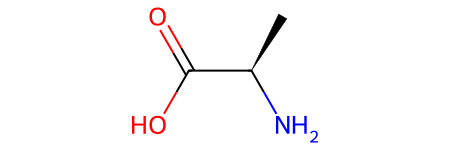

In [49]:
from rdkit import Chem

mol_a = Chem.MolFromSmiles(smiles_a)

mol_b

In [50]:
import torch

graph_a = smiles_to_graph(smiles_a, 6.0)
graph_b = smiles_to_graph(smiles_b, 6.0)

print("Atom features identical:",
      torch.equal(graph_a.x, graph_b.x))

print("Edge indices identical:",
      torch.equal(graph_a.edge_index, graph_b.edge_index))

print("Bond features identical:",
      torch.equal(graph_a.edge_attr, graph_b.edge_attr))

Atom features identical: True
Edge indices identical: True
Bond features identical: True


In [51]:
from rdkit import Chem

for name, smiles in [("A", smiles_a), ("B", smiles_b)]:
    mol = Chem.MolFromSmiles(smiles)
    atom = mol.GetAtomWithIdx(1)

    print(
        name,
        "Chiral tag:", atom.GetChiralTag(),
        "CIP:", atom.GetProp("_CIPCode")
    )

A Chiral tag: CHI_TETRAHEDRAL_CCW CIP: S
B Chiral tag: CHI_TETRAHEDRAL_CW CIP: R


In [52]:
#Encode Chirality
from rdkit import Chem
import numpy as np

CHIRAL_TAGS = [
    Chem.rdchem.ChiralType.CHI_UNSPECIFIED,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW,
    Chem.rdchem.ChiralType.CHI_OTHER,
]

def chirality_features(atom):
    tag = atom.GetChiralTag()
    return np.array(
        [int(tag == t) for t in CHIRAL_TAGS],
        dtype=np.float32
    )

for name, smiles in [("A", smiles_a), ("B", smiles_b)]:
    mol = Chem.MolFromSmiles(smiles)
    atom = mol.GetAtomWithIdx(1)

    print(name, chirality_features(atom))

A [0. 0. 1. 0.]
B [0. 1. 0. 0.]


In [53]:
def smiles_to_graph_chiral(smiles, y):
    # Reuse our original graph converter
    graph = smiles_to_graph(smiles, y)

    mol = Chem.MolFromSmiles(smiles)

    # One chirality vector per atom
    chiral_features = np.stack([
        chirality_features(atom)
        for atom in mol.GetAtoms()
    ])

    # Append four features to the existing 34
    graph.x = torch.cat(
        [
            graph.x,
            torch.tensor(chiral_features, dtype=torch.float32)
        ],
        dim=1
    )

    return graph

In [54]:
#6.0 is simply a dummy pIC50 label for constructing the graphs
graph_a_chiral = smiles_to_graph_chiral(smiles_a, 6.0)
graph_b_chiral = smiles_to_graph_chiral(smiles_b, 6.0)

print("Atom feature shape A:", graph_a_chiral.x.shape)
print("Atom feature shape B:", graph_b_chiral.x.shape)

print(
    "Atom features identical:",
    torch.equal(graph_a_chiral.x, graph_b_chiral.x)
)

print(
    "Connectivity identical:",
    torch.equal(
        graph_a_chiral.edge_index,
        graph_b_chiral.edge_index
    )
)

print("Chiral center A:", graph_a_chiral.x[1, -4:])
print("Chiral center B:", graph_b_chiral.x[1, -4:])

Atom feature shape A: torch.Size([6, 38])
Atom feature shape B: torch.Size([6, 38])
Atom features identical: False
Connectivity identical: True
Chiral center A: tensor([0., 0., 1., 0.])
Chiral center B: tensor([0., 1., 0., 0.])


In [55]:
from rdkit import Chem

n_with_chirality = 0
n_total_centers = 0

for smiles in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smiles)

    centers = Chem.FindMolChiralCenters(
        mol,
        includeUnassigned=False
    )

    if centers:
        n_with_chirality += 1
        n_total_centers += len(centers)

print("Total molecules:", len(df))
print("Molecules with assigned chirality:", n_with_chirality)
print(
    "Percentage:",
    round(100 * n_with_chirality / len(df), 2)
)
print("Total assigned chiral centers:", n_total_centers)

Total molecules: 6287
Molecules with assigned chirality: 968
Percentage: 15.4
Total assigned chiral centers: 3162


In [56]:
#Check Chirality in Validation Data set
import numpy as np
from rdkit import Chem

def has_assigned_chirality(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return bool(
        Chem.FindMolChiralCenters(
            mol,
            includeUnassigned=False
        )
    )

chirality_mask = np.array([
    has_assigned_chirality(s)
    for s in df["canonical_smiles"]
])

val_chirality_mask = chirality_mask[gnn_val_idx]

print("Validation molecules:", len(gnn_val_idx))
print("With assigned chirality:", val_chirality_mask.sum())
print("Without assigned chirality:", (~val_chirality_mask).sum())
print("Percentage with chirality:",
      round(100 * val_chirality_mask.mean(), 2))

Validation molecules: 930
With assigned chirality: 145
Without assigned chirality: 785
Percentage with chirality: 15.59


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import torch

model.eval()

predictions = []
targets = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)

        predictions.extend(
            model(batch).cpu().numpy()
        )
        targets.extend(
            batch.y.cpu().numpy()
        )

predictions = np.array(predictions)
targets = np.array(targets)

assert len(predictions) == len(gnn_val_idx) == 930

for name, mask in [
    ("Assigned chirality", val_chirality_mask),
    ("No assigned chirality", ~val_chirality_mask)
]:
    mae = mean_absolute_error(
        targets[mask],
        predictions[mask]
    )

    rmse = np.sqrt(mean_squared_error(
        targets[mask],
        predictions[mask]
    ))

    print(
        f"{name:22s} "
        f"n={mask.sum():3d} "
        f"MAE={mae:.3f} "
        f"RMSE={rmse:.3f}"
    )

Assigned chirality     n=145 MAE=0.810 RMSE=1.013
No assigned chirality  n=785 MAE=0.947 RMSE=1.220


In [58]:
#Check whether the activity distributions differ
for name, mask in [
    ("Assigned chirality", val_chirality_mask),
    ("No assigned chirality", ~val_chirality_mask)
]:
    y = targets[mask]

    print(
        f"{name:22s} "
        f"n={len(y):3d} "
        f"mean={y.mean():.3f} "
        f"std={y.std():.3f} "
        f"min={y.min():.3f} "
        f"max={y.max():.3f}"
    )

Assigned chirality     n=145 mean=5.712 std=1.257 min=3.345 max=9.538
No assigned chirality  n=785 mean=6.030 std=1.518 min=2.497 max=14.301


In [59]:
class AChEGNNChiral(AChEGNN):
    def __init__(self, hidden_dim=64):
        super().__init__(hidden_dim=hidden_dim)

        # Replace the original 34 -> 64 atom encoder
        self.atom_encoder = nn.Linear(38, hidden_dim)

In [60]:
chiral_graphs = [
    smiles_to_graph_chiral(smiles, y)
    for smiles, y in zip(
        df["canonical_smiles"],
        df["pIC50"]
    )
]

chiral_train_graphs = [
    chiral_graphs[int(i)] for i in gnn_train_idx
]

chiral_val_graphs = [
    chiral_graphs[int(i)] for i in gnn_val_idx
]

chiral_train_loader = DataLoader(
    chiral_train_graphs,
    batch_size=64,
    shuffle=True
)

chiral_val_loader = DataLoader(
    chiral_val_graphs,
    batch_size=64,
    shuffle=False
)

print("Total graphs:", len(chiral_graphs))
print("Training graphs:", len(chiral_train_graphs))
print("Validation graphs:", len(chiral_val_graphs))
print("Atom feature dimension:", chiral_graphs[0].x.shape[1])

Total graphs: 6287
Training graphs: 4099
Validation graphs: 930
Atom feature dimension: 38


In [61]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn

def train_gnn(model, train_loader, val_loader,
              seed=42, max_epochs=60, patience=10):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    loss_fn = nn.MSELoss()

    best_val_mse = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(1, max_epochs + 1):

        model.train()

        for batch in train_loader:
            batch = batch.to(device)

            optimizer.zero_grad()

            predictions = model(batch)
            loss = loss_fn(predictions, batch.y)

            loss.backward()
            optimizer.step()

        model.eval()
        total_squared_error = 0.0
        total_molecules = 0

        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)

                predictions = model(batch)

                total_squared_error += (
                    (predictions - batch.y) ** 2
                ).sum().item()

                total_molecules += batch.y.numel()

        val_mse = total_squared_error / total_molecules

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)

    return model, best_epoch, best_val_mse

In [62]:
#Initialize both GNNs reproducibly
import random
import numpy as np
import torch
from torch_geometric.loader import DataLoader

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_loaders(train_data, val_data, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dl = DataLoader(
        train_data,
        batch_size=64,
        shuffle=True,
        generator=generator
    )

    val_dl = DataLoader(
        val_data,
        batch_size=64,
        shuffle=False
    )

    return train_dl, val_dl


# Original 34-feature model
set_seed(SEED)
baseline_model = AChEGNN(hidden_dim=64)

baseline_train_loader, baseline_val_loader = make_loaders(
    train_graphs, val_graphs, SEED
)


# Chirality-aware 38-feature model
set_seed(SEED)
chiral_model = AChEGNNChiral(hidden_dim=64)

chiral_train_loader, chiral_val_loader = make_loaders(
    chiral_train_graphs, chiral_val_graphs, SEED
)


print("Baseline parameters:",
      sum(p.numel() for p in baseline_model.parameters()))

print("Chiral parameters:",
      sum(p.numel() for p in chiral_model.parameters()))

print("Baseline input dimension:",
      baseline_model.atom_encoder.in_features)

print("Chiral input dimension:",
      chiral_model.atom_encoder.in_features)

Baseline parameters: 19457
Chiral parameters: 19713
Baseline input dimension: 34
Chiral input dimension: 38


In [63]:
# Train original 34-feature GNN
baseline_train_loader, baseline_val_loader = make_loaders(
    train_graphs, val_graphs, SEED
)

baseline_model, baseline_epoch, baseline_mse = train_gnn(
    baseline_model,
    baseline_train_loader,
    baseline_val_loader,
    seed=SEED
)

print(
    f"Baseline: best epoch={baseline_epoch}, "
    f"validation MSE={baseline_mse:.4f}, "
    f"RMSE={np.sqrt(baseline_mse):.4f}"
)


# Train chirality-aware 38-feature GNN
chiral_train_loader, chiral_val_loader = make_loaders(
    chiral_train_graphs, chiral_val_graphs, SEED
)

chiral_model, chiral_epoch, chiral_mse = train_gnn(
    chiral_model,
    chiral_train_loader,
    chiral_val_loader,
    seed=SEED
)

print(
    f"Chiral:   best epoch={chiral_epoch}, "
    f"validation MSE={chiral_mse:.4f}, "
    f"RMSE={np.sqrt(chiral_mse):.4f}"
)

Baseline: best epoch=53, validation MSE=1.2640, RMSE=1.1243
Chiral:   best epoch=60, validation MSE=1.3362, RMSE=1.1559


In [64]:
# Train chirality aware 38-feature GNN
from sklearn.metrics import mean_absolute_error
import numpy as np
import torch

def get_predictions(model, loader):
    model.eval()
    predictions = []
    targets = []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)

            predictions.extend(
                model(batch).cpu().numpy()
            )
            targets.extend(
                batch.y.cpu().numpy()
            )

    return np.array(targets), np.array(predictions)


y_base, pred_base = get_predictions(
    baseline_model, baseline_val_loader
)

y_chiral, pred_chiral = get_predictions(
    chiral_model, chiral_val_loader
)

assert np.allclose(y_base, y_chiral)
assert len(y_base) == len(val_chirality_mask) == 930

for name, mask in [
    ("Assigned chirality", val_chirality_mask),
    ("No assigned chirality", ~val_chirality_mask),
    ("All molecules", np.ones(930, dtype=bool))
]:
    mae_base = mean_absolute_error(
        y_base[mask], pred_base[mask]
    )

    mae_chiral = mean_absolute_error(
        y_chiral[mask], pred_chiral[mask]
    )

    print(
        f"{name:22s} "
        f"n={mask.sum():3d} "
        f"Baseline MAE={mae_base:.3f} "
        f"Chiral MAE={mae_chiral:.3f} "
        f"Difference={mae_chiral - mae_base:+.3f}"
    )

Assigned chirality     n=145 Baseline MAE=0.812 Chiral MAE=0.842 Difference=+0.030
No assigned chirality  n=785 Baseline MAE=0.895 Chiral MAE=0.907 Difference=+0.013
All molecules          n=930 Baseline MAE=0.882 Chiral MAE=0.897 Difference=+0.016


In [65]:
from rdkit import Chem

def smiles_without_stereo(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    Chem.RemoveStereochemistry(mol)
    return Chem.MolToSmiles(mol, canonical=True)


stereo_audit = df[
    ["canonical_smiles", "pIC50"]
].copy()

stereo_audit["connectivity_smiles"] = (
    stereo_audit["canonical_smiles"]
    .apply(smiles_without_stereo)
)

stereo_audit["stereo_smiles"] = (
    stereo_audit["canonical_smiles"]
    .apply(
        lambda s: Chem.MolToSmiles(
            Chem.MolFromSmiles(s),
            isomericSmiles=True
        )
    )
)

grouped = stereo_audit.groupby("connectivity_smiles")

n_stereo_variants = grouped["stereo_smiles"].nunique()

stereo_pair_groups = n_stereo_variants[
    n_stereo_variants > 1
].index

stereo_pairs = stereo_audit[
    stereo_audit["connectivity_smiles"].isin(stereo_pair_groups)
]

print("Connectivity groups with multiple stereoisomers:",
      len(stereo_pair_groups))

print("Molecules in those groups:",
      len(stereo_pairs))

print("\nExample groups:")
for key, group in list(
    stereo_pairs.groupby("connectivity_smiles")
)[:3]:
    print(
        group[["stereo_smiles", "pIC50"]]
        .to_string(index=False)
    )
    print()

Connectivity groups with multiple stereoisomers: 138
Molecules in those groups: 319

Example groups:
                                 stereo_smiles    pIC50
     C#CCN(C)C(C)Cc1cccc(OC(=O)N(C)C2CCCCC2)c1 5.061981
 C#CCN(C)[C@H](C)Cc1cccc(OC(=O)N(C)C2CCCCC2)c1 5.102373
C#CCN(C)[C@@H](C)Cc1cccc(OC(=O)N(C)C2CCCCC2)c1 5.200659

                               stereo_smiles    pIC50
 C#CCN(C)[C@H](C)Cc1cccc(OC(=O)N(C)CCCCCC)c1 5.698970
C#CCN(C)[C@@H](C)Cc1cccc(OC(=O)N(C)CCCCCC)c1 5.468521
     C#CCN(C)C(C)Cc1cccc(OC(=O)N(C)CCCCCC)c1 5.514279

                             stereo_smiles    pIC50
C#CCN[C@@H]1CCc2cc(Cl)c(OC(=O)N(C)CCC)cc21 4.357535
     C#CCNC1CCc2cc(Cl)c(OC(=O)N(C)CCC)cc21 4.357535



In [66]:
# Stereochemistry sometimes matters a lot
from rdkit import Chem
import numpy as np

def has_fully_assigned_tetrahedral_stereo(smiles):
    mol = Chem.MolFromSmiles(smiles)

    centers = Chem.FindMolChiralCenters(
        mol,
        includeUnassigned=True
    )

    return (
        len(centers) > 0
        and all(label != "?" for _, label in centers)
    )


specified = stereo_audit[
    stereo_audit["stereo_smiles"].apply(
        has_fully_assigned_tetrahedral_stereo
    )
].copy()

# Keep groups with at least two distinct specified structures.
n_variants = specified.groupby(
    "connectivity_smiles"
)["stereo_smiles"].nunique()

eligible_groups = n_variants[n_variants >= 2].index

specified_pairs = specified[
    specified["connectivity_smiles"].isin(eligible_groups)
].copy()

# Calculate the activity range within each connectivity group.
activity_ranges = specified_pairs.groupby(
    "connectivity_smiles"
)["pIC50"].agg(lambda x: x.max() - x.min())

print("Groups with multiple specified stereoisomers:",
      len(activity_ranges))

print("Molecules in these groups:",
      len(specified_pairs))

print("Median activity range:",
      round(activity_ranges.median(), 3))

print("90th percentile activity range:",
      round(activity_ranges.quantile(0.90), 3))

print("Maximum activity range:",
      round(activity_ranges.max(), 3))

Groups with multiple specified stereoisomers: 57
Molecules in these groups: 120
Median activity range: 0.403
90th percentile activity range: 2.192
Maximum activity range: 3.088


In [67]:
val_indices = set(map(int, gnn_val_idx))

specified_pairs = specified_pairs.copy()

specified_pairs["dataset_index"] = specified_pairs.index

specified_pairs["is_validation"] = (
    specified_pairs["dataset_index"].isin(val_indices)
)

validation_stereo = specified_pairs[
    specified_pairs["is_validation"]
]

print(
    "Specified stereoisomer molecules in validation:",
    len(validation_stereo)
)

print(
    "Connectivity groups represented in validation:",
    validation_stereo["connectivity_smiles"].nunique()
)

val_group_counts = validation_stereo.groupby(
    "connectivity_smiles"
)["stereo_smiles"].nunique()

print(
    "Groups with >=2 specified stereoisomers in validation:",
    (val_group_counts >= 2).sum()
)

Specified stereoisomer molecules in validation: 11
Connectivity groups represented in validation: 8
Groups with >=2 specified stereoisomers in validation: 3


In [68]:
import pandas as pd
import numpy as np

# Predictions are ordered according to gnn_val_idx,
# because validation DataLoaders use shuffle=False.
prediction_table = pd.DataFrame({
    "dataset_index": np.asarray(gnn_val_idx, dtype=int),
    "baseline_pred": pred_base,
    "chiral_pred": pred_chiral
})

stereo_comparison = validation_stereo.merge(
    prediction_table,
    on="dataset_index",
    how="inner"
)

# Keep only groups with >=2 distinct specified stereoisomers
group_counts = stereo_comparison.groupby(
    "connectivity_smiles"
)["stereo_smiles"].nunique()

paired_groups = group_counts[group_counts >= 2].index

paired_comparison = stereo_comparison[
    stereo_comparison["connectivity_smiles"].isin(paired_groups)
].copy()

for group_number, (_, group) in enumerate(
    paired_comparison.groupby("connectivity_smiles"),
    start=1
):
    print(f"\nGroup {group_number}")

    print(
        group[
            ["stereo_smiles", "pIC50",
             "baseline_pred", "chiral_pred"]
        ].round(3).to_string(index=False)
    )

    print(
        "Observed pIC50 range:",
        round(group["pIC50"].max() - group["pIC50"].min(), 3)
    )

    print(
        "Baseline predicted range:",
        round(group["baseline_pred"].max() -
              group["baseline_pred"].min(), 3)
    )

    print(
        "Chiral predicted range:",
        round(group["chiral_pred"].max() -
              group["chiral_pred"].min(), 3)
    )


Group 1
                                                stereo_smiles  pIC50  baseline_pred  chiral_pred
 CCOC(=O)CC[C@H](NC(=O)OCc1ccccc1)C(=O)NCCC1CCN(Cc2ccccc2)CC1  5.302          6.971        6.706
CCOC(=O)CC[C@@H](NC(=O)OCc1ccccc1)C(=O)NCCC1CCN(Cc2ccccc2)CC1  5.523          6.971        7.138
Observed pIC50 range: 0.221
Baseline predicted range: 0.0
Chiral predicted range: 0.432

Group 2
                                  stereo_smiles  pIC50  baseline_pred  chiral_pred
 COC(=O)C1=C(C)O[P@](=O)(OC)CC[C@H]1COCc1ccccc1  5.222          6.116        5.906
COC(=O)C1=C(C)O[P@@](=O)(OC)CC[C@H]1COCc1ccccc1  4.456          6.116        5.855
Observed pIC50 range: 0.766
Baseline predicted range: 0.0
Chiral predicted range: 0.051

Group 3
                                                          stereo_smiles  pIC50  baseline_pred  chiral_pred
 Cl.Cl.N[C@H](Cc1c[nH]c2ccccc12)C(=O)NCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2  8.161          7.145        6.525
Cl.Cl.N[C@@H](Cc1c[nH]c2ccccc12)C(=O)NCCCCC

In [69]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from torch_geometric.loader import DataLoader

# No shuffling: deterministic evaluation
train_eval_loader = DataLoader(
    train_graphs, batch_size=64, shuffle=False
)

val_eval_loader = DataLoader(
    val_graphs, batch_size=64, shuffle=False
)

def report_metrics(model, loader, name):
    y_true, y_pred = get_predictions(model, loader)

    print(
        f"{name:12s} "
        f"MAE={mean_absolute_error(y_true, y_pred):.3f}  "
        f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):.3f}  "
        f"R2={r2_score(y_true, y_pred):.3f}"
    )

report_metrics(baseline_model, train_eval_loader, "Training")
report_metrics(baseline_model, val_eval_loader, "Validation")

Training     MAE=0.874  RMSE=1.160  R2=0.426
Validation   MAE=0.882  RMSE=1.124  R2=0.426


In [70]:
#Test a deeper GNN
class AChEGNNDeep(nn.Module):
    def __init__(self, hidden_dim=64, num_layers=4):
        super().__init__()

        self.atom_encoder = nn.Linear(34, hidden_dim)
        self.bond_encoder = nn.Linear(7, hidden_dim)

        self.convs = nn.ModuleList()

        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
            self.convs.append(GINEConv(mlp))

        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x = self.atom_encoder(data.x)
        edge_attr = self.bond_encoder(data.edge_attr)

        for conv in self.convs:
            x = F.relu(
                conv(x, data.edge_index, edge_attr)
            )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).squeeze(-1)


set_seed(42)

deep_model = AChEGNNDeep(
    hidden_dim=64,
    num_layers=4
)

print(
    "Deep GNN parameters:",
    sum(p.numel() for p in deep_model.parameters())
)

Deep GNN parameters: 36097


In [149]:
# Recreate DataLoaders with the same random seed
deep_train_loader, deep_val_loader = make_loaders(
    train_graphs,
    val_graphs,
    seed=42
)

# Train the four-layer GNN
deep_model, deep_epoch, deep_mse = train_gnn(
    deep_model,
    deep_train_loader,
    deep_val_loader,
    seed=42,
    max_epochs=60,
    patience=10
)

print(f"Best epoch: {deep_epoch}")
print(f"Validation MSE: {deep_mse:.4f}")

# Evaluate on both training and validation data
report_metrics(deep_model, train_eval_loader, "Training")
report_metrics(deep_model, val_eval_loader, "Validation")


Best epoch: 13
Validation MSE: 1.1344
Training     MAE=0.747  RMSE=1.006  R2=0.568
Validation   MAE=0.815  RMSE=1.065  R2=0.485


In [72]:
import copy

# Preserve the original 60-epoch checkpoint
deep_model_60_state = copy.deepcopy(deep_model.state_dict())
deep_model_60_val_mse = deep_mse

# Fine-tune from the current checkpoint
optimizer = torch.optim.Adam(
    deep_model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

loss_fn = nn.MSELoss()

best_mse = deep_model_60_val_mse
best_state = copy.deepcopy(deep_model.state_dict())
best_extra_epoch = 0
wait = 0

for epoch in range(1, 41):
    deep_model.train()

    for batch in deep_train_loader:
        batch = batch.to(device)

        optimizer.zero_grad()
        predictions = deep_model(batch)
        loss = loss_fn(predictions, batch.y)
        loss.backward()
        optimizer.step()

    deep_model.eval()
    squared_error = 0.0
    n = 0

    with torch.no_grad():
        for batch in deep_val_loader:
            batch = batch.to(device)
            predictions = deep_model(batch)

            squared_error += (
                (predictions - batch.y) ** 2
            ).sum().item()
            n += batch.y.numel()

    mse = squared_error / n

    if mse < best_mse:
        best_mse = mse
        best_state = copy.deepcopy(deep_model.state_dict())
        best_extra_epoch = epoch
        wait = 0
    else:
        wait += 1

    if wait >= 10:
        break

deep_model.load_state_dict(best_state)

print("Best additional epoch:", best_extra_epoch)
print("Original validation MSE:", round(deep_model_60_val_mse, 4))
print("Fine-tuned validation MSE:", round(best_mse, 4))

report_metrics(deep_model, train_eval_loader, "Training")
report_metrics(deep_model, val_eval_loader, "Validation")

Best additional epoch: 22
Original validation MSE: 1.1977
Fine-tuned validation MSE: 1.1186
Training     MAE=0.757  RMSE=1.014  R2=0.561
Validation   MAE=0.813  RMSE=1.058  R2=0.492


In [73]:
torch.save(
    {
        "model_state_dict": deep_model.state_dict(),
        "hidden_dim": 64,
        "num_layers": 4,
        "atom_features": 34,
        "bond_features": 7,
        "validation_mae": 0.813,
        "validation_mse": best_mse,
        "seed": 42,
    },
    "ache_gnn_4layer_best.pt"
)

print("Saved: ache_gnn_4layer_best.pt")

Saved: ache_gnn_4layer_best.pt


In [74]:
# Day 21 — Step 1: Inspect available predictions

candidate_names = [
    "rf_model",
    "rf",
    "rf_val_pred",
    "y_val_pred_rf",
    "X_val",
    "X_val_rf",
    "gnn_val_idx",
    "val_graphs",
    "deep_model",
    "pred_base",
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        shape = getattr(obj, "shape", None)

        if shape is None:
            try:
                shape = f"length={len(obj)}"
            except TypeError:
                shape = "not applicable"

        print(f"{name:18s} FOUND    {shape}")
    else:
        print(f"{name:18s} missing")

rf_model           missing
rf                 missing
rf_val_pred        missing
y_val_pred_rf      missing
X_val              missing
X_val_rf           missing
gnn_val_idx        FOUND    (930,)
val_graphs         FOUND    length=930
deep_model         FOUND    not applicable
pred_base          FOUND    (930,)


In [75]:
#Reconstruct RF model
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

# Morgan count fingerprints
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

X = np.array([
    morgan_gen.GetCountFingerprintAsNumPy(
        Chem.MolFromSmiles(smiles)
    )
    for smiles in df["canonical_smiles"]
])

y = df["pIC50"].to_numpy()

# Exactly the same molecule indices as the GNN
X_rf_train = X[gnn_train_idx]
X_rf_val = X[gnn_val_idx]

y_rf_train = y[gnn_train_idx]
y_rf_val = y[gnn_val_idx]

print("Training fingerprints:", X_rf_train.shape)
print("Validation fingerprints:", X_rf_val.shape)
print("Targets aligned:",
      np.allclose(y_rf_val, y_base))

Training fingerprints: (4099, 2048)
Validation fingerprints: (930, 2048)
Targets aligned: True


In [76]:
#Retraining RF model
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# New Random Forest baseline
rf_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_rf_train, y_rf_train)

# Random Forest predictions
rf_val_pred = rf_model.predict(X_rf_val)

# Fine-tuned 4-layer GNN predictions
y_gnn, gnn_val_pred = get_predictions(
    deep_model,
    val_eval_loader
)

assert np.allclose(y_rf_val, y_gnn)

def print_metrics(name, y_true, y_pred):
    print(
        f"{name:15s} "
        f"MAE={mean_absolute_error(y_true, y_pred):.3f}  "
        f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):.3f}  "
        f"R2={r2_score(y_true, y_pred):.3f}"
    )

print_metrics("Random Forest", y_rf_val, rf_val_pred)
print_metrics("4-layer GNN", y_gnn, gnn_val_pred)

Random Forest   MAE=0.661  RMSE=0.907  R2=0.626
4-layer GNN     MAE=0.813  RMSE=1.058  R2=0.492


In [77]:
#Analyze prediction errors molecule by molecule
from scipy.stats import pearsonr, spearmanr
import numpy as np

# Signed prediction errors
rf_errors = rf_val_pred - y_rf_val
gnn_errors = gnn_val_pred - y_rf_val

# Absolute prediction errors
rf_abs = np.abs(rf_errors)
gnn_abs = np.abs(gnn_errors)

# Compare model errors
abs_corr = pearsonr(rf_abs, gnn_abs)
signed_corr = pearsonr(rf_errors, gnn_errors)

rf_wins = np.sum(rf_abs < gnn_abs)
gnn_wins = np.sum(gnn_abs < rf_abs)
ties = np.sum(np.isclose(rf_abs, gnn_abs))

print(f"Absolute-error Pearson correlation: {abs_corr.statistic:.3f}")
print(f"Signed-error Pearson correlation:   {signed_corr.statistic:.3f}")

print(f"\nRF better:  {rf_wins} molecules ({100 * rf_wins / len(rf_abs):.1f}%)")
print(f"GNN better: {gnn_wins} molecules ({100 * gnn_wins / len(rf_abs):.1f}%)")
print(f"Ties:       {ties} molecules")

Absolute-error Pearson correlation: 0.634
Signed-error Pearson correlation:   0.783

RF better:  567 molecules (61.0%)
GNN better: 363 molecules (39.0%)
Ties:       0 molecules


In [78]:
#Test whether ensembling helps
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

weights = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]

print(f"{'GNN weight':>12} {'MAE':>10} {'RMSE':>10}")

for w in weights:
    ensemble_pred = (
        (1 - w) * rf_val_pred
        + w * gnn_val_pred
    )

    mae = mean_absolute_error(y_rf_val, ensemble_pred)
    rmse = np.sqrt(
        mean_squared_error(y_rf_val, ensemble_pred)
    )

    print(f"{w:12.2f} {mae:10.3f} {rmse:10.3f}")

  GNN weight        MAE       RMSE
        0.00      0.661      0.907
        0.10      0.660      0.902
        0.25      0.669      0.902
        0.50      0.698      0.927
        0.75      0.748      0.980
        1.00      0.813      1.058


In [79]:
#Recongize the molecules with Activity Cliff
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

# Reproducible sample of 300 molecules
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(df), size=300, replace=False)

sample_smiles = df.iloc[sample_idx]["canonical_smiles"].tolist()
sample_y = df.iloc[sample_idx]["pIC50"].to_numpy()

# Morgan bit fingerprints for Tanimoto similarity
fp_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

fps = [
    fp_gen.GetFingerprint(Chem.MolFromSmiles(s))
    for s in sample_smiles
]

# Find highly similar pairs with large potency differences
cliffs = []
similar_pairs = 0

for i in range(len(fps)):
    for j in range(i + 1, len(fps)):
        sim = DataStructs.TanimotoSimilarity(fps[i], fps[j])

        if sim >= 0.85:
            similar_pairs += 1

            delta = abs(sample_y[i] - sample_y[j])

            if delta >= 2.0:
                cliffs.append((i, j, sim, delta))

print("Total molecule pairs:", len(fps) * (len(fps) - 1) // 2)
print("Highly similar pairs:", similar_pairs)
print("Activity-cliff pairs:", len(cliffs))

if cliffs:
    print("\nExample activity cliff:")
    i, j, sim, delta = max(cliffs, key=lambda x: x[3])
    print("Similarity:", round(sim, 3))
    print("Potency difference:", round(delta, 3), "pIC50")
    print("Molecule A:", sample_smiles[i])
    print("Molecule B:", sample_smiles[j])

Total molecule pairs: 44850
Highly similar pairs: 11
Activity-cliff pairs: 0


In [80]:
#Finding non-zero activity cliffs
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

fp_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Generate fingerprints for the complete dataset
all_fps = [
    fp_gen.GetFingerprint(Chem.MolFromSmiles(s))
    for s in df["canonical_smiles"]
]

all_y = df["pIC50"].to_numpy()

similar_pairs = 0
cliff_pairs = []

# Compare each molecule only with molecules after it
for i in range(len(all_fps) - 1):

    similarities = DataStructs.BulkTanimotoSimilarity(
        all_fps[i],
        all_fps[i + 1:]
    )

    for offset, sim in enumerate(similarities):
        if sim >= 0.85:
            j = i + 1 + offset
            similar_pairs += 1

            delta = abs(all_y[i] - all_y[j])

            if delta >= 2.0:
                cliff_pairs.append((i, j, sim, delta))

print("Highly similar pairs:", similar_pairs)
print("Activity-cliff pairs:", len(cliff_pairs))

if cliff_pairs:
    strongest = max(cliff_pairs, key=lambda x: x[3])
    i, j, sim, delta = strongest

    print("\nLargest activity cliff:")
    print(f"Tanimoto similarity: {sim:.3f}")
    print(f"Absolute ΔpIC50: {delta:.3f}")
    print(f"Approximate IC50 fold difference: {10**delta:.1f}x")
    print("Molecule A:", df.iloc[i]["canonical_smiles"])
    print("Molecule B:", df.iloc[j]["canonical_smiles"])
   

Highly similar pairs: 4094
Activity-cliff pairs: 316

Largest activity cliff:
Tanimoto similarity: 0.887
Absolute ΔpIC50: 7.146
Approximate IC50 fold difference: 14000000.0x
Molecule A: O=C(CCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c2ccccc12
Molecule B: O=C(CCc1c[nH]c2ccccc12)NCCCCCNc1c2c(nc3ccccc13)CCCC2


In [81]:
#Is the extreme cliff an outlier?
import numpy as np

cliff_deltas = np.array([
    delta for i, j, sim, delta in cliff_pairs
])

print("Candidate activity cliffs:", len(cliff_deltas))

print("\nPotency difference distribution:")
print("Minimum:", round(np.min(cliff_deltas), 3))
print("Median:", round(np.median(cliff_deltas), 3))
print("90th percentile:", round(np.percentile(cliff_deltas, 90), 3))
print("95th percentile:", round(np.percentile(cliff_deltas, 95), 3))
print("Maximum:", round(np.max(cliff_deltas), 3))

print("\nExtreme cliffs:")
print("\u0394pIC50 >= 3:", np.sum(cliff_deltas >= 3))
print("\u0394pIC50 >= 4:", np.sum(cliff_deltas >= 4))
print("\u0394pIC50 >= 5:", np.sum(cliff_deltas >= 5))

Candidate activity cliffs: 316

Potency difference distribution:
Minimum: 2.0
Median: 2.573
90th percentile: 3.717
95th percentile: 4.431
Maximum: 7.146

Extreme cliffs:
ΔpIC50 >= 3: 84
ΔpIC50 >= 4: 24
ΔpIC50 >= 5: 10


In [82]:
#How many individual molecules participate in activity cliffs?
from collections import Counter
import numpy as np

# Count how often each molecule appears in a cliff pair
cliff_counts = Counter()

for i, j, sim, delta in cliff_pairs:
    cliff_counts[i] += 1
    cliff_counts[j] += 1
#Extract all the unique elements
cliff_molecules = set(cliff_counts.keys())

print("Total molecules:", len(df))
print("Activity-cliff pairs:", len(cliff_pairs))
print("Unique cliff-associated molecules:", len(cliff_molecules))

print(
    "Fraction of dataset:",
    f"{100 * len(cliff_molecules) / len(df):.1f}%"
)

print("\nCliff participation per molecule:")
print("Median:", np.median(list(cliff_counts.values())))
print("Maximum:", max(cliff_counts.values()))

print("\nTop 5 molecules by cliff participation:")
for idx, count in cliff_counts.most_common(5):
    print(
        f"Index {idx}: {count} cliff pairs, "
        f"pIC50={df.iloc[idx]['pIC50']:.3f}"
    )

Total molecules: 6287
Activity-cliff pairs: 316
Unique cliff-associated molecules: 271
Fraction of dataset: 4.3%

Cliff participation per molecule:
Median: 1.0
Maximum: 16

Top 5 molecules by cliff participation:
Index 1116: 16 cliff pairs, pIC50=6.536
Index 1920: 13 cliff pairs, pIC50=5.533
Index 3390: 13 cliff pairs, pIC50=5.533
Index 28: 11 cliff pairs, pIC50=3.863
Index 792: 9 cliff pairs, pIC50=4.444


In [83]:
#Cliff pairs are not independent observations.
from sklearn.metrics import mean_absolute_error
import numpy as np

# Identify cliff-associated molecules within validation set
is_cliff_val = np.isin(
    gnn_val_idx,
    list(cliff_molecules)
)

# Absolute prediction errors
rf_abs = np.abs(rf_val_pred - y_rf_val)
gnn_abs = np.abs(gnn_val_pred - y_rf_val)

print("Validation molecules:", len(gnn_val_idx))
print("Cliff-associated:", is_cliff_val.sum())
print("Other molecules:", (~is_cliff_val).sum())

print("\nRandom Forest:")
print("Cliff MAE:", round(rf_abs[is_cliff_val].mean(), 3))
print("Other MAE:", round(rf_abs[~is_cliff_val].mean(), 3))

print("\n4-layer GNN:")
print("Cliff MAE:", round(gnn_abs[is_cliff_val].mean(), 3))
print("Other MAE:", round(gnn_abs[~is_cliff_val].mean(), 3))

Validation molecules: 930
Cliff-associated: 34
Other molecules: 896

Random Forest:
Cliff MAE: 1.15
Other MAE: 0.642

4-layer GNN:
Cliff MAE: 1.288
Other MAE: 0.795


In [84]:
# Fraction of validation molecules associated with cliffs
cliff_fraction = is_cliff_val.mean()

# Fraction of total absolute error contributed by cliff molecules
rf_error_share = (
    rf_abs[is_cliff_val].sum() / rf_abs.sum()
)

gnn_error_share = (
    gnn_abs[is_cliff_val].sum() / gnn_abs.sum()
)

print(f"Cliff-associated molecules: {100 * cliff_fraction:.1f}%")

print(
    f"RF total absolute error from cliffs: "
    f"{100 * rf_error_share:.1f}%"
)

print(
    f"GNN total absolute error from cliffs: "
    f"{100 * gnn_error_share:.1f}%"
)

Cliff-associated molecules: 3.7%
RF total absolute error from cliffs: 6.4%
GNN total absolute error from cliffs: 5.8%


In [85]:
#Calculate uncertainty for each molecule
import numpy as np

# Prediction from every individual tree
tree_predictions = np.column_stack([
    tree.predict(X_rf_val)
    for tree in rf_model.estimators_
])

# Mean prediction and tree disagreement
rf_mean = tree_predictions.mean(axis=1)
rf_uncertainty = tree_predictions.std(axis=1)

# Verify consistency with our RF predictions
print(
    "Mean predictions match RF:",
    np.allclose(rf_mean, rf_val_pred)
)

print("Tree predictions shape:", tree_predictions.shape)

print("\nUncertainty distribution:")
print("Minimum:", round(rf_uncertainty.min(), 3))
print("Median:", round(np.median(rf_uncertainty), 3))
print("90th percentile:", round(np.percentile(rf_uncertainty, 90), 3))
print("Maximum:", round(rf_uncertainty.max(), 3))

Mean predictions match RF: True
Tree predictions shape: (930, 300)

Uncertainty distribution:
Minimum: 0.073
Median: 0.758
90th percentile: 1.107
Maximum: 2.615


In [86]:
#Inspect Random Forest
for i, tree in enumerate(rf_model.estimators_[:5]):
    root_feature = tree.tree_.feature[0]
    root_threshold = tree.tree_.threshold[0]

    print(
        f"Tree {i+1}: "
        f"root feature = {root_feature}, "
        f"threshold = {root_threshold:.2f}"
    )

Tree 1: root feature = 1098, threshold = 0.50
Tree 2: root feature = 1098, threshold = 0.50
Tree 3: root feature = 1098, threshold = 0.50
Tree 4: root feature = 1098, threshold = 0.50
Tree 5: root feature = 1098, threshold = 0.50


In [87]:
#Let's examine the next level
for i, tree in enumerate(rf_model.estimators_[:5]):
    t = tree.tree_

    left = t.children_left[0]
    right = t.children_right[0]

    print(f"\nTree {i+1}")
    print("Root feature:", t.feature[0])
    print("Left-child feature:", t.feature[left])
    print("Right-child feature:", t.feature[right])


Tree 1
Root feature: 1098
Left-child feature: 1064
Right-child feature: 1718

Tree 2
Root feature: 1098
Left-child feature: 1064
Right-child feature: 828

Tree 3
Root feature: 1098
Left-child feature: 1064
Right-child feature: 1718

Tree 4
Root feature: 1098
Left-child feature: 1064
Right-child feature: 557

Tree 5
Root feature: 1098
Left-child feature: 1064
Right-child feature: 2008


In [88]:
from scipy.stats import spearmanr
import numpy as np

rf_abs_error = np.abs(rf_val_pred - y_rf_val)

rho, p_value = spearmanr(rf_uncertainty, rf_abs_error)

q25, q75 = np.percentile(rf_uncertainty, [25, 75])

low = rf_uncertainty <= q25
high = rf_uncertainty >= q75

print(f"Spearman correlation: {rho:.3f}")
print(f"p-value: {p_value:.3g}")

print(f"\nLow-uncertainty molecules: {low.sum()}")
print(f"Low-uncertainty MAE: {rf_abs_error[low].mean():.3f}")

print(f"\nHigh-uncertainty molecules: {high.sum()}")
print(f"High-uncertainty MAE: {rf_abs_error[high].mean():.3f}")

Spearman correlation: 0.359
p-value: 1.26e-29

Low-uncertainty molecules: 233
Low-uncertainty MAE: 0.456

High-uncertainty molecules: 233
High-uncertainty MAE: 0.992


In [89]:
#How does error change as we include more uncertain molecules
import numpy as np

order = np.argsort(rf_uncertainty)

print("Fraction retained | Molecules | MAE")
print("-" * 40)

for fraction in [0.25, 0.50, 0.75, 1.00]:
    n = int(np.ceil(fraction * len(order)))
    selected = order[:n]

    mae = rf_abs_error[selected].mean()

    print(
        f"{fraction:>16.0%} | "
        f"{n:>9} | "
        f"{mae:.3f}"
    )

Fraction retained | Molecules | MAE
----------------------------------------
             25% |       233 | 0.456
             50% |       465 | 0.483
             75% |       698 | 0.551
            100% |       930 | 0.661


In [90]:
#
import pandas as pd
import numpy as np

uncertainty_df = pd.DataFrame({
    "uncertainty": rf_uncertainty,
    "absolute_error": rf_abs_error
})

uncertainty_df["bin"] = pd.qcut(
    uncertainty_df["uncertainty"],
    q=5,
    labels=False
)

summary = uncertainty_df.groupby("bin").agg(
    n=("absolute_error", "size"),
    mean_uncertainty=("uncertainty", "mean"),
    mae=("absolute_error", "mean")
)

print(summary.round(3))

       n  mean_uncertainty    mae
bin                              
0    186             0.423  0.410
1    186             0.622  0.568
2    186             0.754  0.509
3    186             0.907  0.791
4    186             1.161  1.026


In [91]:
#Find the nearest training molecule
import numpy as np
from rdkit import DataStructs

# Reuse Day 22 Morgan bit fingerprints
train_fps = [all_fps[i] for i in gnn_train_idx]
val_fps = [all_fps[i] for i in gnn_val_idx]

nearest_train_similarity = []

for val_fp in val_fps:
    similarities = DataStructs.BulkTanimotoSimilarity(
        val_fp,
        train_fps
    )

    nearest_train_similarity.append(max(similarities))

nearest_train_similarity = np.array(
    nearest_train_similarity
)

print("Validation molecules:", len(nearest_train_similarity))

print("\nNearest-training similarity distribution:")
print("Minimum:", round(nearest_train_similarity.min(), 3))
print("25th percentile:", round(np.percentile(nearest_train_similarity, 25), 3))
print("Median:", round(np.median(nearest_train_similarity), 3))
print("75th percentile:", round(np.percentile(nearest_train_similarity, 75), 3))
print("Maximum:", round(nearest_train_similarity.max(), 3))

Validation molecules: 930

Nearest-training similarity distribution:
Minimum: 0.17
25th percentile: 0.595
Median: 0.714
75th percentile: 0.826
Maximum: 1.0


In [92]:
#Does chemical novelty predict model error?
from scipy.stats import spearmanr
import numpy as np

# Actual Random Forest absolute errors
rf_abs_error = np.abs(rf_val_pred - y_rf_val)

rho, p_value = spearmanr(
    nearest_train_similarity,
    rf_abs_error
)

q25, q75 = np.percentile(
    nearest_train_similarity,
    [25, 75]
)

low_similarity = nearest_train_similarity <= q25
high_similarity = nearest_train_similarity >= q75

print(f"Spearman similarity-error correlation: {rho:.3f}")
print(f"p-value: {p_value:.3g}")

print("\nLowest-similarity quartile:")
print("Molecules:", low_similarity.sum())
print("MAE:", round(rf_abs_error[low_similarity].mean(), 3))

print("\nHighest-similarity quartile:")
print("Molecules:", high_similarity.sum())
print("MAE:", round(rf_abs_error[high_similarity].mean(), 3))

Spearman similarity-error correlation: -0.214
p-value: 4.64e-11

Lowest-similarity quartile:
Molecules: 233
MAE: 0.809

Highest-similarity quartile:
Molecules: 233
MAE: 0.537


In [93]:
#Are tree disagreement and chemical novelty related?
from scipy.stats import spearmanr
import numpy as np

rho, p_value = spearmanr(
    nearest_train_similarity,
    rf_uncertainty
)

print(f"Similarity–uncertainty Spearman correlation: {rho:.3f}")
print(f"p-value: {p_value:.3g}")

# Compare tree disagreement in low- and high-similarity groups
q25, q75 = np.percentile(
    nearest_train_similarity,
    [25, 75]
)

low_similarity = nearest_train_similarity <= q25
high_similarity = nearest_train_similarity >= q75

print("\nLowest-similarity quartile:")
print(
    "Mean tree disagreement:",
    round(rf_uncertainty[low_similarity].mean(), 3)
)

print("\nHighest-similarity quartile:")
print(
    "Mean tree disagreement:",
    round(rf_uncertainty[high_similarity].mean(), 3)
)

Similarity–uncertainty Spearman correlation: -0.435
p-value: 3.63e-44

Lowest-similarity quartile:
Mean tree disagreement: 0.917

Highest-similarity quartile:
Mean tree disagreement: 0.644


In [94]:
#Does similarity add information beyond tree disagreement?
import numpy as np

# Divide molecules into lower and higher tree disagreement
uncertainty_median = np.median(rf_uncertainty)

# Divide molecules into lower and higher chemical similarity
similarity_median = np.median(nearest_train_similarity)

for label, uncertainty_mask in [
    ("Lower tree disagreement", rf_uncertainty <= uncertainty_median),
    ("Higher tree disagreement", rf_uncertainty > uncertainty_median)
]:
    low_sim = (
        uncertainty_mask &
        (nearest_train_similarity <= similarity_median)
    )

    high_sim = (
        uncertainty_mask &
        (nearest_train_similarity > similarity_median)
    )

    print(f"\n{label}")

    print(
        f"  Lower similarity: n={low_sim.sum()}, "
        f"MAE={rf_abs_error[low_sim].mean():.3f}"
    )

    print(
        f"  Higher similarity: n={high_sim.sum()}, "
        f"MAE={rf_abs_error[high_sim].mean():.3f}"
    )


Lower tree disagreement
  Lower similarity: n=162, MAE=0.556
  Higher similarity: n=303, MAE=0.444

Higher tree disagreement
  Lower similarity: n=306, MAE=0.855
  Higher similarity: n=159, MAE=0.806


In [95]:
!pip install xgboost
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_rf_train, y_rf_train)

xgb_val_pred = xgb_model.predict(X_rf_val)

print("XGBoost MAE:", round(mean_absolute_error(y_rf_val, xgb_val_pred), 3))
print("XGBoost RMSE:", round(np.sqrt(mean_squared_error(y_rf_val, xgb_val_pred)), 3))
print("XGBoost R²:", round(r2_score(y_rf_val, xgb_val_pred), 3))

XGBoost MAE: 0.696
XGBoost RMSE: 0.914
XGBoost R²: 0.621


In [96]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

svr_model = make_pipeline(
    StandardScaler(),
    SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1,
        gamma="scale"
    )
)

svr_model.fit(X_rf_train, y_rf_train)

svr_val_pred = svr_model.predict(X_rf_val)

print("SVR MAE:", round(mean_absolute_error(y_rf_val, svr_val_pred), 3))
print("SVR RMSE:", round(np.sqrt(mean_squared_error(y_rf_val, svr_val_pred)), 3))
print("SVR R²:", round(r2_score(y_rf_val, svr_val_pred), 3))

SVR MAE: 0.743
SVR RMSE: 1.009
SVR R²: 0.538


In [97]:
#Build the Tanimoto kernel matrices
import numpy as np
from rdkit import DataStructs

train_fps = [all_fps[i] for i in gnn_train_idx]
val_fps = [all_fps[i] for i in gnn_val_idx]

# Training-to-training similarity matrix
K_train = np.array([
    DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    for fp in train_fps
])

# Validation-to-training similarity matrix
K_val = np.array([
    DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    for fp in val_fps
])

print("Training kernel shape:", K_train.shape)
print("Validation kernel shape:", K_val.shape)

print("Training kernel symmetric:",
      np.allclose(K_train, K_train.T))

print("Training diagonal equals 1:",
      np.allclose(np.diag(K_train), 1.0))

Training kernel shape: (4099, 4099)
Validation kernel shape: (930, 4099)
Training kernel symmetric: True
Training diagonal equals 1: True


In [98]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tanimoto_svr = SVR(
    kernel="precomputed",
    C=10,
    epsilon=0.1
)

tanimoto_svr.fit(K_train, y_rf_train)

tanimoto_val_pred = tanimoto_svr.predict(K_val)

print(
    "Tanimoto-SVR MAE:",
    round(mean_absolute_error(y_rf_val, tanimoto_val_pred), 3)
)

print(
    "Tanimoto-SVR RMSE:",
    round(np.sqrt(mean_squared_error(y_rf_val, tanimoto_val_pred)), 3)
)

print(
    "Tanimoto-SVR R²:",
    round(r2_score(y_rf_val, tanimoto_val_pred), 3)
)

print(
    "Number of support vectors:",
    len(tanimoto_svr.support_)
)

Tanimoto-SVR MAE: 0.651
Tanimoto-SVR RMSE: 0.889
Tanimoto-SVR R²: 0.642
Number of support vectors: 3432


In [99]:
#Are the improvements consistent across molecules
import numpy as np

rf_errors = np.abs(rf_val_pred - y_rf_val)
tan_errors = np.abs(tanimoto_val_pred - y_rf_val)

improvement = rf_errors - tan_errors

print("Tanimoto-SVR better:", np.sum(improvement > 0))
print("Random Forest better:", np.sum(improvement < 0))
print("Tied:", np.sum(improvement == 0))

print("\nMean MAE improvement:",
      round(improvement.mean(), 4))

print("Median per-molecule improvement:",
      round(np.median(improvement), 4))

print("90th percentile RF error:",
      round(np.percentile(rf_errors, 90), 3))

print("90th percentile Tanimoto-SVR error:",
      round(np.percentile(tan_errors, 90), 3))

Tanimoto-SVR better: 480
Random Forest better: 450
Tied: 0

Mean MAE improvement: 0.0101
Median per-molecule improvement: 0.0147
90th percentile RF error: 1.437
90th percentile Tanimoto-SVR error: 1.435


In [100]:
#Define a combined reliability group
import numpy as np

# Day 23: RF tree disagreement
uncertainty_threshold = np.median(rf_uncertainty)

# Day 24: nearest-training Tanimoto similarity
similarity_threshold = np.median(nearest_train_similarity)

# Proposed applicability-domain rule
inside_ad = (
    (rf_uncertainty <= uncertainty_threshold) &
    (nearest_train_similarity >= similarity_threshold)
)

outside_ad = ~inside_ad
print("Inside", inside_ad[1:5])
rf_abs_error = np.abs(rf_val_pred - y_rf_val)

print("Uncertainty threshold:",
      round(uncertainty_threshold, 3))
print("Similarity threshold:",
      round(similarity_threshold, 3))

print("\nInside proposed applicability domain:")
print("Molecules:", inside_ad.sum())
print("Coverage:", round(inside_ad.mean(), 3))
print("MAE:", round(rf_abs_error[inside_ad].mean(), 3))

print("\nOutside proposed applicability domain:")
print("Molecules:", outside_ad.sum())
print("MAE:", round(rf_abs_error[outside_ad].mean(), 3))

print("\nFull validation MAE:",
      round(rf_abs_error.mean(), 3))

Inside [ True  True  True False]
Uncertainty threshold: 0.758
Similarity threshold: 0.714

Inside proposed applicability domain:
Molecules: 306
Coverage: 0.329
MAE: 0.446

Outside proposed applicability domain:
Molecules: 624
MAE: 0.766

Full validation MAE: 0.661


In [103]:
#Is combining both indicators better than using either alone?
import numpy as np

rules = {
    "Low RF disagreement only":
        rf_uncertainty <= uncertainty_threshold,

    "High chemical similarity only":
        nearest_train_similarity >= similarity_threshold,

    "Both conditions":
        inside_ad
}

print(f"{'Rule':<31} {'N':>5} {'Coverage':>10} {'MAE':>8}")
print("-" * 59)

for name, mask in rules.items():
    print(
        f"{name:<31} "
        f"{mask.sum():>5} "
        f"{mask.mean():>10.3f} "
        f"{rf_abs_error[mask].mean():>8.3f}"
        )


Rule                                N   Coverage      MAE
-----------------------------------------------------------
Low RF disagreement only          465      0.500    0.483
High chemical similarity only     470      0.505    0.577
Both conditions                   306      0.329    0.446


In [104]:
import numpy as np

# Number of molecules selected by the combined rule
n_selected = int(inside_ad.sum())

# Select exactly the same number using RF disagreement alone
lowest_uncertainty_idx = np.argsort(rf_uncertainty)[:n_selected]

uncertainty_only_matched = np.zeros(
    len(rf_uncertainty),
    dtype=bool
)

uncertainty_only_matched[lowest_uncertainty_idx] = True
print(uncertainty_only_matched[1:5])
print("Matched coverage:", round(n_selected / len(rf_uncertainty), 3))

print("\nUncertainty-only selection:")
print("Molecules:", uncertainty_only_matched.sum())
print(
    "MAE:",
    round(rf_abs_error[uncertainty_only_matched].mean(), 3)
)

print("\nCombined selection:")
print("Molecules:", inside_ad.sum())
print(
    "MAE:",
    round(rf_abs_error[inside_ad].mean(), 3)
)

print("\nMolecules selected by both rules:",
      np.sum(uncertainty_only_matched & inside_ad))

[ True  True  True False]
Matched coverage: 0.329

Uncertainty-only selection:
Molecules: 306
MAE: 0.476

Combined selection:
Molecules: 306
MAE: 0.446

Molecules selected by both rules: 224


In [105]:
#does it achieve lower error simply because it selects fewer molecules?
n = inside_ad.sum()

# Select 306 molecules with the lowest RF tree disagreement
idx = np.argsort(rf_uncertainty)[:n]

uncertainty_mae = rf_abs_error[idx].mean()
combined_mae = rf_abs_error[inside_ad].mean()

print("Matched coverage:", round(n / len(rf_abs_error), 3))
print("Uncertainty-only MAE:", round(uncertainty_mae, 3))
print("Combined-rule MAE:", round(combined_mae, 3))
print("MAE difference (uncertainty - combined):",
      round(uncertainty_mae - combined_mae, 3))

Matched coverage: 0.329
Uncertainty-only MAE: 0.476
Combined-rule MAE: 0.446
MAE difference (uncertainty - combined): 0.029


In [106]:
#Audit our dataset splits
import numpy as np

train_set = set(map(int, gnn_train_idx))
val_set = set(map(int, gnn_val_idx))
test_set = set(map(int, test_idx))

print("Training molecules:", len(train_set))
print("Validation molecules:", len(val_set))
print("Test molecules:", len(test_set))

print("\nIndex overlap checks:")
print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test:", len(train_set & test_set))
print("Validation ∩ Test:", len(val_set & test_set))

all_indices = train_set | val_set | test_set

print("\nUnique indices covered:", len(all_indices))
print("Total dataset molecules:", len(df))

print(
    "Complete partition:",
    all_indices == set(range(len(df)))
)

print(
    "All subsets disjoint:",
    not (train_set & val_set
         or train_set & test_set
         or val_set & test_set)
)

Training molecules: 4099
Validation molecules: 930
Test molecules: 1258

Index overlap checks:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Unique indices covered: 6287
Total dataset molecules: 6287
Complete partition: True
All subsets disjoint: True


In [107]:
#Audit chemical identity and scaffold overlap
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

smiles = df["canonical_smiles"].tolist()
print(smiles[1])
train_smiles = {smiles[i] for i in gnn_train_idx}
val_smiles = {smiles[i] for i in gnn_val_idx}
test_smiles = {smiles[i] for i in test_idx}

print("Canonical SMILES overlap:")
print("Train–Validation:", len(train_smiles & val_smiles))
print("Train–Test:", len(train_smiles & test_smiles))
print("Validation–Test:", len(val_smiles & test_smiles))

# Compute scaffolds once for all molecules
scaffolds = [get_scaffold(s) for s in smiles]

train_scaffolds = {scaffolds[i] for i in gnn_train_idx}
val_scaffolds = {scaffolds[i] for i in gnn_val_idx}
test_scaffolds = {scaffolds[i] for i in test_idx}

print("\nUnique scaffolds:")
print("Train:", len(train_scaffolds))
print("Validation:", len(val_scaffolds))
print("Test:", len(test_scaffolds))

print("\nScaffold overlap:")
print("Train–Validation:", len(train_scaffolds & val_scaffolds))
print("Train–Test:", len(train_scaffolds & test_scaffolds))
print("Validation–Test:", len(val_scaffolds & test_scaffolds))

CN1CC[C@@]2(C)c3cc(OC(=O)Nc4ccccc4)ccc3N(C=O)C12
Canonical SMILES overlap:
Train–Validation: 0
Train–Test: 2
Validation–Test: 0

Unique scaffolds:
Train: 1774
Validation: 453
Test: 821

Scaffold overlap:
Train–Validation: 20
Train–Test: 373
Validation–Test: 100


In [108]:
#Identify the exact overlapping molecules and scaffolds
# 1. Identify exact training/test SMILES duplicates
duplicate_smiles = train_smiles & test_smiles

print("TRAIN–TEST DUPLICATE MOLECULES")

for smi in sorted(duplicate_smiles):
    train_rows = [
        i for i in gnn_train_idx
        if smiles[i] == smi
    ]
    test_rows = [
        i for i in test_idx
        if smiles[i] == smi
    ]

    print("\nSMILES:", smi)
    print("Training rows:", train_rows)
    print("Test rows:", test_rows)

    for i in train_rows + test_rows:
        print(
            " Row:", i,
            "ChEMBL ID:", df.iloc[i]["molecule_chembl_id"],
            "pIC50:", round(float(df.iloc[i]["pIC50"]), 3)
        )

# 2. Inspect shared training/validation scaffolds
shared_scaffolds = train_scaffolds & val_scaffolds

print("\nTRAIN–VALIDATION SHARED SCAFFOLDS")
print("Number:", len(shared_scaffolds))

for scaffold in sorted(shared_scaffolds):
    n_train = sum(
        scaffolds[i] == scaffold for i in gnn_train_idx
    )
    n_val = sum(
        scaffolds[i] == scaffold for i in gnn_val_idx
    )

    print(
        f"Train: {n_train:3d} | "
        f"Validation: {n_val:3d} | "
        f"Scaffold: {scaffold}"
    )

TRAIN–TEST DUPLICATE MOLECULES

SMILES: CC1=C[C@@H]2Cc3nc4cc(Cl)ccc4c(N)c3[C@H](C1)C2
Training rows: [np.int64(277)]
Test rows: [np.int64(1108)]
 Row: 277 ChEMBL ID: CHEMBL1161905 pIC50: 9.367
 Row: 1108 ChEMBL ID: CHEMBL2007996 pIC50: 9.131

SMILES: CC1=C[C@H]2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2
Training rows: [np.int64(1140)]
Test rows: [np.int64(3392)]
 Row: 1140 ChEMBL ID: CHEMBL2021616 pIC50: 7.166
 Row: 3392 ChEMBL ID: CHEMBL4112162 pIC50: 7.866

TRAIN–VALIDATION SHARED SCAFFOLDS
Number: 20
Train:   1 | Validation:   3 | Scaffold: C(=CC[n+]1ccccc1)C[n+]1ccccc1
Train:  19 | Validation:   5 | Scaffold: C1=C(Nc2ccccc2)CC(c2ccccc2)N(c2ccccc2)C1c1ccccc1
Train:   8 | Validation:   2 | Scaffold: C1=CC(c2ccccc2)c2cc3c(nc2O1)CCCC3
Train:   2 | Validation:   2 | Scaffold: C1=CC2Cc3nc4ccccc4c(NCCCCCCCNc4c5c(nc6ccccc46)CCCC5)c3C(C1)C2
Train:   1 | Validation:   1 | Scaffold: C1=Cc2ccccc2C(CCOc2ccccc2)NC1
Train:   2 | Validation:   2 | Scaffold: O=C(NCc1ccccc1)Oc1ccc2c(c1)C1CCNC1C2
Train:   1 

In [109]:
#How much of the validation set shares training scaffolds?
import numpy as np

shared_scaffolds = train_scaffolds & val_scaffolds

# Identify validation molecules whose scaffolds occur in training
val_shared_scaffold = np.array([
    scaffolds[i] in shared_scaffolds
    for i in gnn_val_idx
])

# Identify validation molecules with genuinely unseen scaffolds
val_unseen_scaffold = ~val_shared_scaffold

print("Validation molecules:", len(gnn_val_idx))

print("\nShared-scaffold validation molecules:")
print("Count:", val_shared_scaffold.sum())
print("Fraction:", round(val_shared_scaffold.mean(), 3))

print("\nUnseen-scaffold validation molecules:")
print("Count:", val_unseen_scaffold.sum())
print("Fraction:", round(val_unseen_scaffold.mean(), 3))

print("\nRandom Forest MAE:")
print(
    "Shared scaffolds:",
    round(rf_abs_error[val_shared_scaffold].mean(), 3)
)
print(
    "Unseen scaffolds:",
    round(rf_abs_error[val_unseen_scaffold].mean(), 3)
)

print("\nTanimoto-SVR MAE:")
tan_abs_error = np.abs(tanimoto_val_pred - y_rf_val)

print(
    "Shared scaffolds:",
    round(tan_abs_error[val_shared_scaffold].mean(), 3)
)
print(
    "Unseen scaffolds:",
    round(tan_abs_error[val_unseen_scaffold].mean(), 3)
)

Validation molecules: 930

Shared-scaffold validation molecules:
Count: 53
Fraction: 0.057

Unseen-scaffold validation molecules:
Count: 877
Fraction: 0.943

Random Forest MAE:
Shared scaffolds: 0.607
Unseen scaffolds: 0.664

Tanimoto-SVR MAE:
Shared scaffolds: 0.516
Unseen scaffolds: 0.659


In [110]:
#Check whether scaffold grouping used a different definition
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_chiral_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=True
    )

chiral_scaffolds = [
    get_chiral_scaffold(s)
    for s in df["canonical_smiles"]
]

train_chiral = {
    chiral_scaffolds[i] for i in gnn_train_idx
}

val_chiral = {
    chiral_scaffolds[i] for i in gnn_val_idx
}

shared_chiral = train_chiral & val_chiral

print("Shared scaffolds without chirality:",
      len(train_scaffolds & val_scaffolds))

print("Shared scaffolds with chirality:",
      len(shared_chiral))

print(
    "Validation molecules sharing a chiral scaffold:",
    sum(chiral_scaffolds[i] in shared_chiral
        for i in gnn_val_idx)
)

Shared scaffolds without chirality: 20
Shared scaffolds with chirality: 0
Validation molecules sharing a chiral scaffold: 0


In [111]:
#Check whether the duplicate molecules also have identical fingerprints
from rdkit import DataStructs
import numpy as np

print("TRAIN–TEST DUPLICATE REPRESENTATIONS")

for smi in sorted(train_smiles & test_smiles):
    i_train = next(
        i for i in gnn_train_idx if smiles[i] == smi
    )
    i_test = next(
        i for i in test_idx if smiles[i] == smi
    )

    count_fp_equal = np.array_equal(
        X[i_train], X[i_test]
    )

    bit_fp_similarity = DataStructs.TanimotoSimilarity(
        all_fps[i_train],
        all_fps[i_test]
    )

    print("\nTraining row:", i_train)
    print("Test row:", i_test)
    print("Count fingerprints identical:", count_fp_equal)
    print("Bit fingerprint Tanimoto:", bit_fp_similarity)
    print(
        "Absolute pIC50 difference:",
        round(abs(y[i_train] - y[i_test]), 3)
    )

TRAIN–TEST DUPLICATE REPRESENTATIONS

Training row: 277
Test row: 1108
Count fingerprints identical: True
Bit fingerprint Tanimoto: 1.0
Absolute pIC50 difference: 0.236

Training row: 1140
Test row: 3392
Count fingerprints identical: True
Bit fingerprint Tanimoto: 1.0
Absolute pIC50 difference: 0.7


In [112]:
import numpy as np

# Exclude test molecules with canonical SMILES found in training
clean_test_idx = np.array([
    i for i in test_idx
    if smiles[i] not in train_smiles
], dtype=int)

excluded_test_idx = np.array([
    i for i in test_idx
    if smiles[i] in train_smiles
], dtype=int)

print("Original test size:", len(test_idx))
print("Clean test size:", len(clean_test_idx))
print("Excluded molecules:", len(excluded_test_idx))
print("Excluded indices:", excluded_test_idx.tolist())

clean_test_smiles = {
    smiles[i] for i in clean_test_idx
}

print(
    "Remaining exact SMILES overlap with training:",
    len(clean_test_smiles & train_smiles)
)

print(
    "Remaining exact SMILES overlap with validation:",
    len(clean_test_smiles & val_smiles)
)

print(
    "Clean test indices unique:",
    len(clean_test_idx) == len(set(clean_test_idx))
)

Original test size: 1258
Clean test size: 1256
Excluded molecules: 2
Excluded indices: [1108, 3392]
Remaining exact SMILES overlap with training: 0
Remaining exact SMILES overlap with validation: 0
Clean test indices unique: True


In [113]:
#Freeze our evaluation protocol
import json
import numpy as np

evaluation_protocol = {
    "project": "Human AChE pIC50 prediction",
    "dataset_size": len(df),
    "training_size": len(gnn_train_idx),
    "validation_size": len(gnn_val_idx),
    "original_test_size": len(test_idx),
    "clean_test_size": len(clean_test_idx),

    "excluded_test_indices": sorted(
        excluded_test_idx.tolist()
    ),

    "primary_test_indices": sorted(
        clean_test_idx.tolist()
    ),

    "primary_models": [
        "Random Forest",
        "Tanimoto-kernel SVR"
    ],

    "applicability_domain": {
        "model": "Random Forest",
        "uncertainty_measure": "Standard deviation across trees",
        "uncertainty_threshold": float(uncertainty_threshold),
        "similarity_measure": "Maximum Morgan-bit Tanimoto similarity to training",
        "similarity_threshold": float(similarity_threshold),
        "inside_rule": (
            "uncertainty <= threshold AND "
            "similarity >= threshold"
        )
    },

    "validation_scaffold_definition": (
        "Chirality-aware Bemis-Murcko"
    ),

    "test_interpretation": (
        "Random held-out molecules; "
        "not a strictly scaffold-disjoint test"
    )
}

with open("ache_evaluation_protocol.json", "w") as f:
    json.dump(evaluation_protocol, f, indent=2)

print("Saved: ache_evaluation_protocol.json")
print("Clean test molecules:",
      len(evaluation_protocol["primary_test_indices"]))
print("RF uncertainty threshold:",
      evaluation_protocol["applicability_domain"]
      ["uncertainty_threshold"])
print("Similarity threshold:",
      evaluation_protocol["applicability_domain"]
      ["similarity_threshold"])

Saved: ache_evaluation_protocol.json
Clean test molecules: 1256
RF uncertainty threshold: 0.7581355859721572
Similarity threshold: 0.7142857142857143


In [114]:
#Save the trained models
import joblib
import numpy as np

# Save the fitted models
joblib.dump(rf_model, "ache_rf_frozen.joblib")
joblib.dump(tanimoto_svr, "ache_tanimoto_svr_frozen.joblib")

# Reload them
rf_reloaded = joblib.load("ache_rf_frozen.joblib")
svr_reloaded = joblib.load("ache_tanimoto_svr_frozen.joblib")

# Verify predictions against our existing validation results
rf_reloaded_pred = rf_reloaded.predict(X_rf_val)
svr_reloaded_pred = svr_reloaded.predict(K_val)

print("Random Forest predictions unchanged:",
      np.allclose(rf_reloaded_pred, rf_val_pred))

print("Tanimoto-SVR predictions unchanged:",
      np.allclose(svr_reloaded_pred, tanimoto_val_pred))

print("RF maximum prediction difference:",
      np.max(np.abs(rf_reloaded_pred - rf_val_pred)))

print("SVR maximum prediction difference:",
      np.max(np.abs(svr_reloaded_pred - tanimoto_val_pred)))

Random Forest predictions unchanged: True
Tanimoto-SVR predictions unchanged: True
RF maximum prediction difference: 3.552713678800501e-15
SVR maximum prediction difference: 0.0


In [115]:
#Verify Tanimoto kernel alignment
import numpy as np
from rdkit import DataStructs

# Reconstruct training fingerprints from the frozen training indices
train_fps_check = [
    all_fps[i] for i in gnn_train_idx
]

# Reconstruct the validation-to-training kernel
K_val_check = np.array([
    DataStructs.BulkTanimotoSimilarity(
        all_fps[i], train_fps_check
    )
    for i in gnn_val_idx
])

print("Original K_val shape:", K_val.shape)
print("Rebuilt K_val shape:", K_val_check.shape)

print(
    "Kernel matrices identical:",
    np.array_equal(K_val, K_val_check)
)

print(
    "Maximum kernel difference:",
    np.max(np.abs(K_val - K_val_check))
)

# Check predictions from the rebuilt kernel
pred_check = svr_reloaded.predict(K_val_check)

print(
    "SVR predictions unchanged:",
    np.allclose(pred_check, tanimoto_val_pred)
)

print(
    "Maximum prediction difference:",
    np.max(np.abs(pred_check - tanimoto_val_pred))
)

Original K_val shape: (930, 4099)
Rebuilt K_val shape: (930, 4099)
Kernel matrices identical: True
Maximum kernel difference: 0.0
SVR predictions unchanged: True
Maximum prediction difference: 0.0


In [116]:
#Final Test Performance
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from rdkit import DataStructs

# Frozen test indices and measured activities
test_indices = np.asarray(clean_test_idx, dtype=int)
y_test = df.iloc[test_indices]["pIC50"].to_numpy()

# Random Forest: Morgan count fingerprints
X_test = X[test_indices]
rf_test_pred = rf_reloaded.predict(X_test)

# Tanimoto-SVR: binary Morgan fingerprints
# Columns follow the verified training order
K_test = np.array([
    DataStructs.BulkTanimotoSimilarity(
        all_fps[i], train_fps_check
    )
    for i in test_indices
])

svr_test_pred = svr_reloaded.predict(K_test)

def test_metrics(y_true, y_pred):
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred)
    )

print("Clean test molecules:", len(y_test))
print("Tanimoto test kernel shape:", K_test.shape)

for name, pred in [
    ("Random Forest", rf_test_pred),
    ("Tanimoto-SVR", svr_test_pred)
]:
    mae, rmse, r2 = test_metrics(y_test, pred)
    print(
        f"{name:16s} "
        f"MAE={mae:.3f}  "
        f"RMSE={rmse:.3f}  "
        f"R²={r2:.3f}"
    )

Clean test molecules: 1256
Tanimoto test kernel shape: (1256, 4099)
Random Forest    MAE=0.565  RMSE=0.816  R²=0.697
Tanimoto-SVR     MAE=0.548  RMSE=0.789  R²=0.716


In [117]:
#Does the frozen applicability domain generalize?
import numpy as np
from rdkit import DataStructs

# RF uncertainty: disagreement among the frozen trees
test_tree_predictions = np.column_stack([
    tree.predict(X_test)
    for tree in rf_reloaded.estimators_
])

rf_test_uncertainty = test_tree_predictions.std(axis=1)

# Maximum chemical similarity to the original training set
test_nearest_similarity = np.array([
    max(DataStructs.BulkTanimotoSimilarity(
        all_fps[i], train_fps_check
    ))
    for i in test_indices
])

# Apply the frozen Day 26 thresholds
inside_test_ad = (
    (rf_test_uncertainty <= uncertainty_threshold)
    & (test_nearest_similarity >= similarity_threshold)
)

outside_test_ad = ~inside_test_ad

rf_test_abs_error = np.abs(rf_test_pred - y_test)
svr_test_abs_error = np.abs(svr_test_pred - y_test)

print("Clean test molecules:", len(y_test))
print("Inside AD:", inside_test_ad.sum())
print("Outside AD:", outside_test_ad.sum())
print("AD coverage:", round(inside_test_ad.mean(), 3))

print("\nRandom Forest MAE:")
print("Inside AD:", round(rf_test_abs_error[inside_test_ad].mean(), 3))
print("Outside AD:", round(rf_test_abs_error[outside_test_ad].mean(), 3))
print("Full test:", round(rf_test_abs_error.mean(), 3))

print("\nTanimoto-SVR MAE:")
print("Inside AD:", round(svr_test_abs_error[inside_test_ad].mean(), 3))
print("Outside AD:", round(svr_test_abs_error[outside_test_ad].mean(), 3))
print("Full test:", round(svr_test_abs_error.mean(), 3))

Clean test molecules: 1256
Inside AD: 636
Outside AD: 620
AD coverage: 0.506

Random Forest MAE:
Inside AD: 0.396
Outside AD: 0.74
Full test: 0.565

Tanimoto-SVR MAE:
Inside AD: 0.406
Outside AD: 0.693
Full test: 0.548


In [118]:
#Does the combined rule outperform uncertainty alone at matched coverage?
import numpy as np

n_selected = int(inside_test_ad.sum())

# Select exactly the same number of molecules
# using RF uncertainty alone
uncertainty_order = np.argsort(
    rf_test_uncertainty,
    kind="stable"
)

uncertainty_only_mask = np.zeros(
    len(y_test),
    dtype=bool
)

uncertainty_only_mask[
    uncertainty_order[:n_selected]
] = True

# Compare at identical coverage
combined_mae = rf_test_abs_error[
    inside_test_ad
].mean()

uncertainty_only_mae = rf_test_abs_error[
    uncertainty_only_mask
].mean()

overlap = np.sum(
    inside_test_ad & uncertainty_only_mask
)

print("Selected molecules:", n_selected)
print("Coverage:", round(n_selected / len(y_test), 3))

print("\nRF MAE at matched coverage:")
print("Combined AD:", round(combined_mae, 3))
print("Uncertainty only:", round(uncertainty_only_mae, 3))

print("\nSelection overlap:", overlap)
print("Combined-only molecules:", n_selected - overlap)
print("Uncertainty-only molecules:", n_selected - overlap)

print(
    "\nRelative MAE improvement (%):",
    round(
        100 * (uncertainty_only_mae - combined_mae)
        / uncertainty_only_mae,
        2
    )
)

Selected molecules: 636
Coverage: 0.506

RF MAE at matched coverage:
Combined AD: 0.396
Uncertainty only: 0.376

Selection overlap: 563
Combined-only molecules: 73
Uncertainty-only molecules: 73

Relative MAE improvement (%): -5.25


In [119]:
#Why did the combined rule select worse molecules
import numpy as np

combined_only = (
    inside_test_ad & ~uncertainty_only_mask
)

uncertainty_only = (
    uncertainty_only_mask & ~inside_test_ad
)

both_selected = (
    inside_test_ad & uncertainty_only_mask
)

for name, mask in [
    ("Both methods", both_selected),
    ("Combined AD only", combined_only),
    ("Uncertainty only", uncertainty_only)
]:
    print(f"\n{name}")
    print("Molecules:", mask.sum())
    print(
        "RF MAE:",
        round(rf_test_abs_error[mask].mean(), 3)
    )
    print(
        "Mean RF uncertainty:",
        round(rf_test_uncertainty[mask].mean(), 3)
    )
    print(
        "Mean nearest similarity:",
        round(test_nearest_similarity[mask].mean(), 3)
    )


Both methods
Molecules: 563
RF MAE: 0.363
Mean RF uncertainty: 0.49
Mean nearest similarity: 0.874

Combined AD only
Molecules: 73
RF MAE: 0.644
Mean RF uncertainty: 0.726
Mean nearest similarity: 0.856

Uncertainty only
Molecules: 73
RF MAE: 0.472
Mean RF uncertainty: 0.558
Mean nearest similarity: 0.602


In [120]:
#Paired bootstrap confidence interval
import numpy as np

# Absolute errors from Day 28
rf_errors = np.abs(rf_test_pred - y_test)
svr_errors = np.abs(svr_test_pred - y_test)

# Positive values favor Tanimoto-SVR
paired_difference = rf_errors - svr_errors

observed_delta = paired_difference.mean()

rng = np.random.default_rng(42)
n_bootstrap = 5000
n_test = len(paired_difference)

bootstrap_deltas = np.empty(n_bootstrap)

for b in range(n_bootstrap):
    sample_idx = rng.integers(
        low=0,
        high=n_test,
        size=n_test
    )

    bootstrap_deltas[b] = (
        paired_difference[sample_idx].mean()
    )

ci_lower, ci_upper = np.percentile(
    bootstrap_deltas, [2.5, 97.5]
)

print("Test molecules:", n_test)
print("RF MAE:", round(rf_errors.mean(), 4))
print("SVR MAE:", round(svr_errors.mean(), 4))

print("\nObserved ΔMAE (RF − SVR):",
      round(observed_delta, 4))

print("95% bootstrap CI:",
      (round(ci_lower, 4),
       round(ci_upper, 4)))

print(
    "Fraction of bootstrap replicates ΔMAE > 0:",
    round(np.mean(bootstrap_deltas > 0), 4)
)

print(
    "CI excludes zero:",
    ci_lower > 0 or ci_upper < 0
)

Test molecules: 1256
RF MAE: 0.5654
SVR MAE: 0.548

Observed ΔMAE (RF − SVR): 0.0175
95% bootstrap CI: (np.float64(-0.0048), np.float64(0.0397))
Fraction of bootstrap replicates ΔMAE > 0: 0.9354
CI excludes zero: False


In [121]:
#Is the model difference driven by a few difficult molecules?
import numpy as np

paired_difference = rf_errors - svr_errors

print("Molecules where SVR is better:",
      np.sum(paired_difference > 0))

print("Molecules where RF is better:",
      np.sum(paired_difference < 0))

print("Exact ties:",
      np.sum(paired_difference == 0))

print("\nPaired error difference:")
print("Mean:", round(paired_difference.mean(), 4))
print("Median:", round(np.median(paired_difference), 4))
print("10th percentile:",
      round(np.percentile(paired_difference, 10), 4))
print("90th percentile:",
      round(np.percentile(paired_difference, 90), 4))

# Sensitivity to the largest disagreements
abs_difference = np.abs(paired_difference)

for fraction in [0.01, 0.05, 0.10]:
    cutoff = np.quantile(
        abs_difference, 1 - fraction
    )

    keep = abs_difference < cutoff

    print(
        f"\nExcluding largest {fraction:.0%} disagreements:"
    )
    print("Remaining molecules:", keep.sum())
    print(
        "Mean ΔMAE:",
        round(paired_difference[keep].mean(), 4)
    )

Molecules where SVR is better: 618
Molecules where RF is better: 638
Exact ties: 0

Paired error difference:
Mean: 0.0175
Median: -0.0033
10th percentile: -0.3928
90th percentile: 0.4567

Excluding largest 1% disagreements:
Remaining molecules: 1243
Mean ΔMAE: 0.0171

Excluding largest 5% disagreements:
Remaining molecules: 1193
Mean ΔMAE: 0.0047

Excluding largest 10% disagreements:
Remaining molecules: 1130
Mean ΔMAE: 0.0059


In [122]:
#Which molecules drive the difference?
import pandas as pd
import numpy as np

comparison = pd.DataFrame({
    "test_index": test_indices,
    "SMILES": df.iloc[test_indices]["canonical_smiles"].to_numpy(),
    "true_pIC50": y_test,
    "RF_prediction": rf_test_pred,
    "SVR_prediction": svr_test_pred,
    "RF_abs_error": rf_errors,
    "SVR_abs_error": svr_errors,
    "delta_error": paired_difference
})

print("Five molecules where SVR helps most:")
display(
    comparison.nlargest(5, "delta_error")[
        ["test_index", "true_pIC50",
         "RF_abs_error", "SVR_abs_error",
         "delta_error", "SMILES"]
    ]
)

print("\nFive molecules where RF helps most:")
display(
    comparison.nsmallest(5, "delta_error")[
        ["test_index", "true_pIC50",
         "RF_abs_error", "SVR_abs_error",
         "delta_error", "SMILES"]
    ]
)

Five molecules where SVR helps most:


,test_index,true_pIC50,RF_abs_error,SVR_abs_error,delta_error,SMILES
1101,1578,4.253550,1.872973,0.065348,1.807624,COc1cc(C#N)cc[n+]1C.F[B-](F)(F)F
353,6046,8.332547,4.024369,2.311762,1.712606,Cc1ccc(O)c(CNc2c(N)n(C)c(=O)n(C)c2=O)c1
444,6122,5.394695,1.910917,0.263930,1.646988,CC(C)(C)c1ccc(/C=N/CCNc2c3c(nc4ccccc24)CCCCC3)...
1139,3916,14.301030,6.175515,4.540168,1.635347,S=C(CCCCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c...
395,228,8.744727,2.208902,0.610749,1.598153,CNC(=O)Oc1cccc(CN(C)CCCCCCCOc2ccc3c(c2)C/C(=C\...



Five molecules where RF helps most:


,test_index,true_pIC50,RF_abs_error,SVR_abs_error,delta_error,SMILES
683,4025,14.301030,1.156199,3.364796,-2.208597,O=C(CCCCCNc1c2c(nc3ccc(F)cc13)CCCC2)NCCc1c[nH]...
660,3837,14.301030,0.918825,3.026170,-2.107345,O=C(CCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c2cc...
646,1467,8.000000,2.179108,3.810323,-1.631214,CCOP(=O)(OCC)Oc1ccc([N+](=O)[O-])cc1
180,2405,5.481486,0.005417,1.614955,-1.609538,CN1CCC(C2Cc3ccccc3C2=O)CC1
354,1103,11.096910,1.507417,3.104105,-1.596687,O=C(CCCCCCNc1c2c(nc3cc(Cl)cc(Cl)c13)CCCC2)NCCc...


In [123]:
#quality-control check
import numpy as np

extreme_indices = np.flatnonzero(
    df["pIC50"].to_numpy() >= 12
)

extreme = df.iloc[extreme_indices][
    ["molecule_chembl_id", "pIC50", "canonical_smiles"]
].copy()

extreme["IC50_nM_implied"] = (
    10 ** (9 - extreme["pIC50"])
)

print("Molecules with pIC50 >= 12:", len(extreme))

display(
    extreme[
        ["molecule_chembl_id", "pIC50", "IC50_nM_implied"]
    ].sort_values("pIC50", ascending=False).head(20)
)

Molecules with pIC50 >= 12: 19


,molecule_chembl_id,pIC50,IC50_nM_implied
1099,CHEMBL199454,14.301030,0.000005
1102,CHEMBL199538,14.301030,0.000005
1105,CHEMBL199748,14.301030,0.000005
1106,CHEMBL199861,14.301030,0.000005
1107,CHEMBL200008,14.301030,0.000005
3837,CHEMBL4443426,14.301030,0.000005
2945,CHEMBL383663,14.301030,0.000005
3864,CHEMBL4448350,14.301030,0.000005
3883,CHEMBL4455677,14.301030,0.000005
3920,CHEMBL4468781,14.301030,0.000005


In [124]:
#Retrieve original ChEMBL activity records
import pandas as pd
from chembl_webresource_client.new_client import new_client

activity = new_client.activity

molecule_ids = [
    "CHEMBL199454",
    "CHEMBL4443426"
]

records = []

for mol_id in molecule_ids:
    results = activity.filter(
        molecule_chembl_id=mol_id,
        target_chembl_id="CHEMBL220",
        standard_type="IC50"
    )

    for record in results:
        records.append({
            "molecule_chembl_id": mol_id,
            "activity_id": record.get("activity_id"),
            "assay_chembl_id": record.get("assay_chembl_id"),
            "standard_relation": record.get("standard_relation"),
            "standard_value": record.get("standard_value"),
            "standard_units": record.get("standard_units"),
            "published_value": record.get("published_value"),
            "published_units": record.get("published_units"),
            "document_chembl_id": record.get("document_chembl_id"),
            "data_validity_comment": record.get("data_validity_comment")
        })

audit_df = pd.DataFrame(records)

print("Number of retrieved activity records:", len(audit_df))
display(audit_df)

Number of retrieved activity records: 2


,molecule_chembl_id,activity_id,assay_chembl_id,standard_relation,standard_value,standard_units,published_value,published_units,document_chembl_id,data_validity_comment
0,CHEMBL199454,18997028,CHEMBL4342697,=,0.000005,nM,None,None,CHEMBL4342404,Outside typical range
1,CHEMBL4443426,18997016,CHEMBL4342697,=,0.000005,nM,None,None,CHEMBL4342404,Outside typical range


In [125]:
from chembl_webresource_client.new_client import new_client
import pandas as pd
import numpy as np

extreme_molecules = df.loc[
    np.isclose(df["pIC50"], 14.301030),
    "molecule_chembl_id"
].tolist()

records = []

for mol_id in extreme_molecules:
    for r in new_client.activity.filter(
        molecule_chembl_id=mol_id,
        target_chembl_id="CHEMBL220",
        standard_type="IC50"
    ):
        records.append({
            "molecule": mol_id,
            "assay": r.get("assay_chembl_id"),
            "document": r.get("document_chembl_id"),
            "value_nM": r.get("standard_value"),
            "relation": r.get("standard_relation"),
            "validity": r.get("data_validity_comment")
        })

provenance = pd.DataFrame(records)

print("Extreme molecules:", len(extreme_molecules))
print("Activity records:", len(provenance))

print("\nAssay counts:")
print(provenance["assay"].value_counts())

print("\nValidity comments:")
print(provenance["validity"].fillna("No comment").value_counts())

display(provenance)

Extreme molecules: 17
Activity records: 17

Assay counts:
assay
CHEMBL4342697    17
Name: count, dtype: int64

Validity comments:
validity
Outside typical range    17
Name: count, dtype: int64


,molecule,assay,document,value_nM,relation,validity
0,CHEMBL199454,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
1,CHEMBL199538,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
2,CHEMBL199748,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
3,CHEMBL199861,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
4,CHEMBL200008,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
5,CHEMBL383663,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
6,CHEMBL4443426,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
7,CHEMBL4448350,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
8,CHEMBL4455677,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range
9,CHEMBL4467284,CHEMBL4342697,CHEMBL4342404,0.000005,=,Outside typical range


In [132]:
#Sensitivity to flagged ChEMBL activity labels
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Day 28 clean test set, in the same order as predictions
test_ids = df.iloc[test_indices]["molecule_chembl_id"].to_numpy()
print(len(test_ids))
# Day 29: all 17 molecules traced to one flagged assay
flagged_ids = set(
    df.loc[
        np.isclose(df["pIC50"], 14.301030),
        "molecule_chembl_id"
    ]
)

is_flagged_test = np.isin(test_ids, list(flagged_ids))
keep = ~is_flagged_test

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

print("Clean test molecules:", len(y_test))
print("Flagged extreme-label test molecules:", is_flagged_test.sum())
print("Remaining after diagnostic exclusion:", keep.sum())

print("\nRF — original:")
print(metrics(y_test, rf_test_pred))

print("\nRF — excluding flagged labels:")
print(metrics(y_test[keep], rf_test_pred[keep]))

print("\nTanimoto-SVR — original:")
print(metrics(y_test, svr_test_pred))

print("\nTanimoto-SVR — excluding flagged labels:")
print(metrics(y_test[keep], svr_test_pred[keep]))

print("\nFlagged subset only:")
if is_flagged_test.any():
    print("RF:", metrics(
        y_test[is_flagged_test],
        rf_test_pred[is_flagged_test]
    ))
    print("SVR:", metrics(
        y_test[is_flagged_test],
        svr_test_pred[is_flagged_test]
    ))

1256
Clean test molecules: 1256
Flagged extreme-label test molecules: 4
Remaining after diagnostic exclusion: 1252

RF — original:
{'MAE': 0.5654332740813495, 'RMSE': np.float64(0.8155325340429109), 'R2': 0.696993311603413}

RF — excluding flagged labels:
{'MAE': 0.559716725050928, 'RMSE': np.float64(0.7961941332036098), 'R2': 0.6796536998542431}

Tanimoto-SVR — original:
{'MAE': 0.5479692198025803, 'RMSE': np.float64(0.7888766817124871), 'R2': 0.7164772772256736}

Tanimoto-SVR — excluding flagged labels:
{'MAE': 0.538912238072048, 'RMSE': np.float64(0.765567332465795), 'R2': 0.7038248937473828}

Flagged subset only:
RF: {'MAE': 2.3547131206032827, 'RMSE': np.float64(3.2281178768461247), 'R2': 0.0}
SVR: {'MAE': 3.3828045014591424, 'RMSE': np.float64(3.4587974733373836), 'R2': 0.0}


In [128]:
#Chemical similarity results
import numpy as np

# Already computed on Day 24
val_similarity = np.asarray(nearest_train_similarity)

# Already computed on Day 28
test_similarity = np.asarray(test_nearest_similarity)

def summarize_similarity(values):
    return {
        "n": len(values),
        "mean": round(values.mean(), 4),
        "median": round(np.median(values), 4),
        "q25": round(np.percentile(values, 25), 4),
        "q75": round(np.percentile(values, 75), 4),
        "fraction_below_0.5": round(np.mean(values < 0.5), 4),
        "fraction_above_0.85": round(np.mean(values >= 0.85), 4)
    }

print("Validation similarity:")
print(summarize_similarity(val_similarity))

print("\nClean test similarity:")
print(summarize_similarity(test_similarity))

print("\nDifference in median similarity (test − validation):")
print(round(
    np.median(test_similarity) - np.median(val_similarity),
    4
))

Validation similarity:
{'n': 930, 'mean': np.float64(0.7067), 'median': np.float64(0.7143), 'q25': np.float64(0.5949), 'q75': np.float64(0.8261), 'fraction_below_0.5': np.float64(0.1376), 'fraction_above_0.85': np.float64(0.2204)}

Clean test similarity:
{'n': 1256, 'mean': np.float64(0.77), 'median': np.float64(0.7931), 'q25': np.float64(0.6798), 'q75': np.float64(0.8837), 'fraction_below_0.5': np.float64(0.078), 'fraction_above_0.85': np.float64(0.328)}

Difference in median similarity (test − validation):
0.0788


In [129]:
#Test-set scaffold generalization
import numpy as np
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import mean_absolute_error

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

# Use existing training and clean-test indices
train_scaffolds = {
    get_scaffold(df.iloc[i]["canonical_smiles"])
    for i in gnn_train_idx
}

test_scaffolds = [
    get_scaffold(df.iloc[i]["canonical_smiles"])
    for i in test_indices
]

seen_scaffold = np.array([
    s in train_scaffolds for s in test_scaffolds
])

unseen_scaffold = ~seen_scaffold

print("Clean test molecules:", len(test_indices))
print("Seen-scaffold molecules:", seen_scaffold.sum())
print("Unseen-scaffold molecules:", unseen_scaffold.sum())

for label, mask in [
    ("Seen scaffolds", seen_scaffold),
    ("Unseen scaffolds", unseen_scaffold)
]:
    print(f"\n{label}:")
    print("Molecules:", mask.sum())

    if mask.any():
        print(
            "RF MAE:",
            round(mean_absolute_error(
                y_test[mask], rf_test_pred[mask]
            ), 4)
        )
        print(
            "SVR MAE:",
            round(mean_absolute_error(
                y_test[mask], svr_test_pred[mask]
            ), 4)
        )
        print(
            "Median nearest-train similarity:",
            round(np.median(
                test_nearest_similarity[mask]
            ), 4)
        )

Clean test molecules: 1256
Seen-scaffold molecules: 736
Unseen-scaffold molecules: 520

Seen scaffolds:
Molecules: 736
RF MAE: 0.516
SVR MAE: 0.4971
Median nearest-train similarity: 0.8198

Unseen scaffolds:
Molecules: 520
RF MAE: 0.6355
SVR MAE: 0.6199
Median nearest-train similarity: 0.7246


In [175]:
#Experiment-1: Audit our saved artifacts
from pathlib import Path
import json
import joblib
import pandas as pd

required_files = {
    "Cleaned dataset": "ache_ic50_clean.csv",
    "Frozen RF model": "ache_rf_frozen.joblib",
    "Frozen SVR model": "ache_tanimoto_svr_frozen.joblib",
    "Evaluation protocol": "ache_evaluation_protocol.json",
}

print("Working directory:", Path.cwd())
print("\nArtifact audit:")

for name, filename in required_files.items():
    path = Path(filename)

    if path.exists():
        print(
            f"[OK] {name}: {filename} "
            f"({path.stat().st_size / 1024:.1f} KB)"
        )
    else:
        print(f"[MISSING] {name}: {filename}")

protocol_path = Path("ache_evaluation_protocol.json")

if protocol_path.exists():
    with protocol_path.open("r") as f:
        protocol = json.load(f)

    print("\nSaved protocol keys:")
    for key in protocol:
        print(" -", key)

data_path = Path("ache_ic50_clean.csv")

if data_path.exists():
    saved_df = pd.read_csv(data_path)

    print("\nSaved dataset shape:", saved_df.shape)
    print("Saved dataset columns:", saved_df.columns.tolist())

Working directory: [local path omitted]

Artifact audit:
[OK] Cleaned dataset: ache_ic50_clean.csv (532.1 KB)
[OK] Frozen RF model: ache_rf_frozen.joblib (47420.9 KB)
[OK] Frozen SVR model: ache_tanimoto_svr_frozen.joblib (68.3 KB)
[OK] Evaluation protocol: ache_evaluation_protocol.json (12.9 KB)

Saved protocol keys:
 - project
 - dataset_size
 - training_size
 - validation_size
 - original_test_size
 - clean_test_size
 - excluded_test_indices
 - primary_test_indices
 - primary_models
 - applicability_domain
 - validation_scaffold_definition
 - test_interpretation

Saved dataset shape: (6287, 4)
Saved dataset columns: ['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'n_measurements']


In [176]:
#Experiment2:Validate the frozen evaluation protocol: row-index misalignment
import numpy as np

n_rows = len(saved_df)

test_idx = np.asarray(
    protocol["primary_test_indices"],
    dtype=int
)

excluded_idx = np.asarray(
    protocol["excluded_test_indices"],
    dtype=int
)

checks = {
    "Dataset size matches protocol":
        n_rows == protocol["dataset_size"],

    "Clean test size matches protocol":
        len(test_idx) == protocol["clean_test_size"],

    "All test indices are valid":
        np.all((test_idx >= 0) & (test_idx < n_rows)),

    "Test indices are unique":
        len(np.unique(test_idx)) == len(test_idx),

    "Excluded indices absent from clean test":
        len(np.intersect1d(test_idx, excluded_idx)) == 0,

    "Exactly two excluded indices":
        len(excluded_idx) == 2,
}

print("Protocol consistency checks:\n")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nSaved dataset size:", n_rows)
print("Saved clean test size:", len(test_idx))
print("Excluded test indices:", excluded_idx.tolist())

print("\nAll checks passed:", all(checks.values()))

Protocol consistency checks:

PASS: Dataset size matches protocol
PASS: Clean test size matches protocol
PASS: All test indices are valid
PASS: Test indices are unique
PASS: Excluded indices absent from clean test
PASS: Exactly two excluded indices

Saved dataset size: 6287
Saved clean test size: 1256
Excluded test indices: [1108, 3392]

All checks passed: True


In [136]:
#Experiment3: Can we reconstruct the SVR training kernel?
import numpy as np

print("Saved protocol keys:")
print(list(protocol.keys()))

print("\nTraining indices available in notebook:",
      "gnn_train_idx" in globals())

if "gnn_train_idx" in globals():
    train_idx = np.asarray(gnn_train_idx, dtype=int)

    print("Training molecules:", len(train_idx))
    print("Unique training indices:", len(np.unique(train_idx)))
    print("First 10 training indices:", train_idx[:10].tolist())

print("\nValidation indices available in notebook:",
      "gnn_val_idx" in globals())

if "gnn_val_idx" in globals():
    val_idx = np.asarray(gnn_val_idx, dtype=int)

    print("Validation molecules:", len(val_idx))
    print("Unique validation indices:", len(np.unique(val_idx)))

print("\nSaved training indices in protocol:",
      any("train" in key.lower() and "indices" in key.lower()
          for key in protocol))

print("Saved validation indices in protocol:",
      any("val" in key.lower() and "indices" in key.lower()
          for key in protocol))

Saved protocol keys:
['project', 'dataset_size', 'training_size', 'validation_size', 'original_test_size', 'clean_test_size', 'excluded_test_indices', 'primary_test_indices', 'primary_models', 'applicability_domain', 'validation_scaffold_definition', 'test_interpretation']

Training indices available in notebook: True
Training molecules: 4099
Unique training indices: 4099
First 10 training indices: [5252, 106, 3783, 1344, 5146, 3089, 1965, 1354, 2275, 2670]

Validation indices available in notebook: True
Validation molecules: 930
Unique validation indices: 930

Saved training indices in protocol: False
Saved validation indices in protocol: False


In [137]:
#Experiment4: Freeze the original split indices
from pathlib import Path
import numpy as np
import hashlib

# Original split indices — preserve their existing order
train_indices = np.asarray(gnn_train_idx, dtype=np.int64)
val_indices = np.asarray(gnn_val_idx, dtype=np.int64)
test_indices_saved = np.asarray(
    protocol["primary_test_indices"],
    dtype=np.int64
)

# Save exact split membership AND ordering
split_path = Path("ache_frozen_splits.npz")

np.savez_compressed(
    split_path,
    train_idx=train_indices,
    val_idx=val_indices,
    test_idx=test_indices_saved
)

# Verify round-trip
with np.load(split_path) as splits:
    checks = {
        "Training indices preserved":
            np.array_equal(splits["train_idx"], train_indices),

        "Validation indices preserved":
            np.array_equal(splits["val_idx"], val_indices),

        "Test indices preserved":
            np.array_equal(splits["test_idx"], test_indices_saved),

        "Training and validation disjoint":
            len(np.intersect1d(
                splits["train_idx"], splits["val_idx"]
            )) == 0,

        "Training and test disjoint":
            len(np.intersect1d(
                splits["train_idx"], splits["test_idx"]
            )) == 0,

        "Validation and test disjoint":
            len(np.intersect1d(
                splits["val_idx"], splits["test_idx"]
            )) == 0,
    }

# Hash the exact CSV bytes
csv_path = Path("ache_ic50_clean.csv")
csv_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
"""best practice for reproducibility, data integrity, and auditing-
By logging the SHA-256 hash, you have absolute proof of which exact version of the data was used to train your model."""
print("Frozen split file:", split_path.resolve())
print("CSV SHA-256:", csv_sha256)

print("\nVerification:")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nAll checks passed:", all(checks.values()))

Frozen split file: [local path omitted]
CSV SHA-256: cd3dafeb44d4f7a649c02976f365cc48f706aeba742acafa4575291d97bc357b

Verification:
PASS: Training indices preserved
PASS: Validation indices preserved
PASS: Test indices preserved
PASS: Training and validation disjoint
PASS: Training and test disjoint
PASS: Validation and test disjoint

All checks passed: True


In [138]:
#Experiment5: Verify dataset row alignment
import numpy as np
import pandas as pd

# Compare saved CSV against the original notebook DataFrame
same_ids = np.array_equal(
    saved_df["molecule_chembl_id"].to_numpy(),
    df["molecule_chembl_id"].to_numpy()
)

same_smiles = np.array_equal(
    saved_df["canonical_smiles"].to_numpy(),
    df["canonical_smiles"].to_numpy()
)

same_labels = np.allclose(
    saved_df["pIC50"].to_numpy(),
    df["pIC50"].to_numpy(),
    rtol=0,
    atol=1e-10,
    equal_nan=True
)

checks = {
    "Molecule ID order matches": same_ids,
    "SMILES order matches": same_smiles,
    "pIC50 values match": same_labels,
}

print("Dataset row-alignment checks:\n")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nAll checks passed:", all(checks.values()))

Dataset row-alignment checks:

PASS: Molecule ID order matches
PASS: SMILES order matches
PASS: pIC50 values match

All checks passed: True


In [140]:
#Experiment6: Reproduce RF predictions from disk
import numpy as np
import pandas as pd
import joblib

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load data and split indices from disk
data_reloaded = pd.read_csv("ache_ic50_clean.csv")

with np.load("ache_frozen_splits.npz") as splits:
    test_idx_reloaded = splits["test_idx"].copy()

# 2. Load the frozen Random Forest
rf_disk = joblib.load("ache_rf_frozen.joblib")

# 3. Rebuild Morgan COUNT fingerprints
count_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

test_smiles = data_reloaded.iloc[
    test_idx_reloaded
]["canonical_smiles"]

X_test_rebuilt = np.array([
    count_generator.GetCountFingerprintAsNumPy(
        Chem.MolFromSmiles(smiles)
    )
    for smiles in test_smiles
])

# 4. Predict using the frozen model
rf_pred_rebuilt = rf_disk.predict(X_test_rebuilt)

y_test_rebuilt = data_reloaded.iloc[
    test_idx_reloaded
]["pIC50"].to_numpy()

# 5. Compare with the original Day 28 predictions
max_difference = np.max(
    np.abs(rf_pred_rebuilt - rf_test_pred)
)

print("Rebuilt fingerprint shape:", X_test_rebuilt.shape)
print("Maximum prediction difference:", max_difference)

print(
    "Predictions match:",
    np.allclose(
        rf_pred_rebuilt,
        rf_test_pred,
        rtol=0,
        atol=1e-10
    )
)

print("\nReconstructed RF test metrics:")
print("MAE:", mean_absolute_error(y_test_rebuilt, rf_pred_rebuilt))
print("RMSE:", np.sqrt(mean_squared_error(y_test_rebuilt, rf_pred_rebuilt)))
print("R2:", r2_score(y_test_rebuilt, rf_pred_rebuilt))

Rebuilt fingerprint shape: (1256, 2048)
Maximum prediction difference: 10.211093708140183
Predictions match: False

Reconstructed RF test metrics:
MAE: 0.5654332740813495
RMSE: 0.8155325340429109
R2: 0.696993311603413


In [141]:
#Experiment7: Check prediction alignment
import numpy as np
from sklearn.metrics import mean_absolute_error

print("1. Target alignment")
print(
    "Original and rebuilt y match:",
    np.array_equal(y_test, y_test_rebuilt)
)

print("\n2. Prediction comparison")
print("Original predictions shape:", rf_test_pred.shape)
print("Rebuilt predictions shape:", rf_pred_rebuilt.shape)

print(
    "Original prediction range:",
    np.min(rf_test_pred),
    np.max(rf_test_pred)
)

print(
    "Rebuilt prediction range:",
    np.min(rf_pred_rebuilt),
    np.max(rf_pred_rebuilt)
)

print("\n3. MAE using the same rebuilt targets")
print(
    "Original predictions:",
    mean_absolute_error(y_test_rebuilt, rf_test_pred)
)

print(
    "Rebuilt predictions:",
    mean_absolute_error(y_test_rebuilt, rf_pred_rebuilt)
)

print("\n4. First five values")
print("Original y:   ", y_test[:5])
print("Rebuilt y:    ", y_test_rebuilt[:5])
print("Original pred:", rf_test_pred[:5])
print("Rebuilt pred: ", rf_pred_rebuilt[:5])

1. Target alignment
Original and rebuilt y match: False

2. Prediction comparison
Original predictions shape: (1256,)
Rebuilt predictions shape: (1256,)
Original prediction range: 2.6039926801782154 13.403383357347437
Rebuilt prediction range: 2.603992680178216 13.403383357347437

3. MAE using the same rebuilt targets
Original predictions: 1.5114826806366959
Rebuilt predictions: 0.5654332740813495

4. First five values
Original y:    [5.91009489 8.19382003 6.22081491 4.60205999 8.57511836]
Rebuilt y:     [7.25963731 6.92081875 4.30103    4.39794001 4.71197446]
Original pred: [5.96531893 6.98626131 5.60618799 4.71878554 8.19405051]
Rebuilt pred:  [7.16312628 3.70237399 4.71145471 3.41297121 5.31896072]


In [185]:
#Experiment8: Verify and correct the ordering
import numpy as np

original_idx = np.asarray(test_indices, dtype=int)
saved_idx = np.asarray(test_idx_reloaded, dtype=int)

print("Same order:", np.array_equal(original_idx, saved_idx))

print(
    "Same index membership:",
    np.array_equal(
        np.sort(original_idx),
        np.sort(saved_idx)
    )
)

print("Original first 10 indices:", original_idx[:10])
print("Saved first 10 indices:", saved_idx[:10])

if np.array_equal(np.sort(original_idx), np.sort(saved_idx)):

    # Position of each original index in the saved ordering
    saved_position = {
        idx: position
        for position, idx in enumerate(saved_idx[:5])
    }
    print(saved_position.keys())
    saved_position = {
        idx: position
        for position, idx in enumerate(saved_idx)
    }

    reorder = np.array([
        saved_position[idx]
        for idx in original_idx
    ])

    aligned_y = y_test_rebuilt[reorder]
    aligned_rf_pred = rf_pred_rebuilt[reorder]

    print("\nAfter alignment:")

    print(
        "Targets match:",
        np.allclose(aligned_y, y_test, rtol=0, atol=1e-10)
    )

    print(
        "Predictions match:",
        np.allclose(
            aligned_rf_pred,
            rf_test_pred,
            rtol=0,
            atol=1e-10
        )
    )

    print(
        "Maximum prediction difference:",
        np.max(np.abs(aligned_rf_pred - rf_test_pred))
    )

Same order: False
Same index membership: True
Original first 10 indices: [4441 3658 6067 5319 1539 3336  296 4217 3907 6041]
Saved first 10 indices: [ 8 14 15 17 19 23 29 31 33 37]
dict_keys([np.int64(8), np.int64(14), np.int64(15), np.int64(17), np.int64(19)])

After alignment:
Targets match: True
Predictions match: True
Maximum prediction difference: 5.329070518200751e-15


In [143]:
#Experiment10: Reconstruct Tanimoto-SVR predictions
import numpy as np
import joblib
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Reload the frozen training and test indices
with np.load("ache_frozen_splits.npz") as splits:
    train_idx_disk = splits["train_idx"].copy()
    test_idx_disk = splits["test_idx"].copy()

# 2. Verify original training order
print(
    "Training order preserved:",
    np.array_equal(train_idx_disk, np.asarray(gnn_train_idx))
)

# 3. Load frozen SVR
svr_disk = joblib.load("ache_tanimoto_svr_frozen.joblib")

# 4. Generate Morgan BINARY fingerprints
fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

train_fps_disk = [
    fp_generator.GetFingerprint(
        Chem.MolFromSmiles(s)
    )
    for s in data_reloaded.iloc[train_idx_disk]["canonical_smiles"]
]

test_fps_disk = [
    fp_generator.GetFingerprint(
        Chem.MolFromSmiles(s)
    )
    for s in data_reloaded.iloc[test_idx_disk]["canonical_smiles"]
]

# 5. Reconstruct test-to-training Tanimoto kernel
K_test_disk = np.array([
    DataStructs.BulkTanimotoSimilarity(fp, train_fps_disk)
    for fp in test_fps_disk
])

# 6. Predict and evaluate
svr_pred_disk = svr_disk.predict(K_test_disk)
y_test_disk = data_reloaded.iloc[test_idx_disk]["pIC50"].to_numpy()

print("\nKernel shape:", K_test_disk.shape)
print("MAE:", mean_absolute_error(y_test_disk, svr_pred_disk))
print("RMSE:", np.sqrt(mean_squared_error(y_test_disk, svr_pred_disk)))
print("R2:", r2_score(y_test_disk, svr_pred_disk))

# 7. Compare predictions by molecule identity
original_idx = np.asarray(test_indices)
saved_position = {
    idx: pos for pos, idx in enumerate(test_idx_disk)
}
reorder = np.array([saved_position[idx] for idx in original_idx])

svr_pred_aligned = svr_pred_disk[reorder]

print("\nPredictions match original:",
      np.allclose(svr_pred_aligned, svr_test_pred,
                  rtol=0, atol=1e-10))

print("Maximum prediction difference:",
      np.max(np.abs(svr_pred_aligned - svr_test_pred)))

Training order preserved: True

Kernel shape: (1256, 4099)
MAE: 0.5479692198025804
RMSE: 0.7888766817124873
R2: 0.7164772772256736

Predictions match original: True
Maximum prediction difference: 0.0


In [144]:
#Experiment11: Record the software environment
import sys
import json
import platform
import importlib.metadata as metadata
from pathlib import Path

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "rdkit",
    "joblib",
    "scipy",
    "torch",
    "torch-geometric",
]

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {}
}

for package in packages:
    try:
        environment["packages"][package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        environment["packages"][package] = None

output_path = Path("ache_environment_versions.json")

with output_path.open("w") as f:
    json.dump(environment, f, indent=2)

print(json.dumps(environment, indent=2))
print("\nSaved:", output_path.resolve())

{
  "python": "3.11.15",
  "platform": "Linux-6.8.0-138-generic-x86_64-with-glibc2.35",
  "packages": {
    "numpy": "2.4.6",
    "pandas": "3.0.3",
    "scikit-learn": "1.9.1",
    "rdkit": "2026.3.6",
    "joblib": "1.6.0",
    "scipy": "1.17.1",
    "torch": "2.14.1",
    "torch-geometric": "2.8.0.post1"
  }
}

Saved: [local output path omitted]


In [186]:
#Experiment12: Create a minimal reproducibility specification
from pathlib import Path
import json

with open("ache_environment_versions.json") as f:
    environment = json.load(f)

inference_packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "rdkit",
    "joblib",
    "scipy",
]

requirements = []

for package in inference_packages:
    version = environment["packages"].get(package)

    if version is None:
        raise ValueError(f"Missing version for {package}")

    requirements.append(f"{package}=={version}")

output_path = Path("ache_requirements_inference.txt")
output_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print(output_path.read_text())
print("Saved:", output_path.resolve())

#ache_ic50_clean.csv
#ache_rf_frozen.joblib
#ache_tanimoto_svr_frozen.joblib
#ache_evaluation_protocol.json
#ache_frozen_splits.npz
#ache_environment_versions.json
#ache_requirements_inference.txt

numpy==2.4.6
pandas==3.0.3
scikit-learn==1.9.1
rdkit==2026.3.6
joblib==1.6.0
scipy==1.17.1

Saved: [local output path omitted]


In [146]:
#Save our GNN model
import torch
from pathlib import Path

checkpoint_path = Path("ache_gine_4layer_frozen.pt")

torch.save(
    {
        "model_state_dict": deep_model.state_dict(),
        "architecture": "4-layer GINE",
        "validation_mae": 0.813,
        "validation_r2": 0.492,
        "training_size": 4099,
        "validation_size": 930,
        "note": (
            "Architecture details and graph featurization "
            "must be documented separately."
        ),
    },
    checkpoint_path
)

print("Saved:", checkpoint_path.resolve())
print("Size (KB):", round(checkpoint_path.stat().st_size / 1024, 1))

# Verify checkpoint can be read
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Architecture:", checkpoint["architecture"])
print("Number of parameter tensors:",
      len(checkpoint["model_state_dict"]))
print("Validation MAE:", checkpoint["validation_mae"])

Saved: [local output path omitted]
Size (KB): 150.7
Architecture: 4-layer GINE
Number of parameter tensors: 26
Validation MAE: 0.813


In [147]:
#Verify the saved weights
import torch

checkpoint = torch.load(
    "ache_gine_4layer_frozen.pt",
    map_location="cpu",
    weights_only=True
)

saved_weights = checkpoint["model_state_dict"]
current_weights = deep_model.state_dict()

keys_match = set(saved_weights) == set(current_weights)

weights_match = keys_match and all(
    torch.equal(
        saved_weights[name].cpu(),
        current_weights[name].cpu()
    )
    for name in saved_weights
)

print("Parameter names match:", keys_match)
print("Parameter values match:", weights_match)

print(
    "Total parameters:",
    sum(t.numel() for t in saved_weights.values())
)

Parameter names match: True
Parameter values match: True
Total parameters: 36101


In [151]:
import torch
from pathlib import Path

old_path = Path("ache_gnn_4layer_best.pt")
new_path = Path("ache_gine_4layer_frozen.pt")

print("Day 21 checkpoint exists:", old_path.exists())
print("New checkpoint exists:", new_path.exists())

old = torch.load(old_path, map_location="cpu", weights_only=True)
new = torch.load(new_path, map_location="cpu", weights_only=True)

old_weights = old["model_state_dict"]
new_weights = new["model_state_dict"]

same_keys = set(old_weights) == set(new_weights)

same_weights = same_keys and all(
    torch.equal(old_weights[k], new_weights[k])
    for k in old_weights
)

print("Parameter names match:", same_keys)
print("Parameter values match:", same_weights)

print(
    "Day 21 parameter count:",
    sum(t.numel() for t in old_weights.values())
)

print(
    "New parameter count:",
    sum(t.numel() for t in new_weights.values())
)

print("Day 21 validation MSE:", old.get("validation_mse"))
print("Day 21 metadata:", list(old.keys()))

Day 21 checkpoint exists: True
New checkpoint exists: True
Parameter names match: True
Parameter values match: True
Day 21 parameter count: 36101
New parameter count: 36101
Day 21 validation MSE: 1.1185832649148921
Day 21 metadata: ['model_state_dict', 'hidden_dim', 'num_layers', 'atom_features', 'bond_features', 'validation_mae', 'validation_mse', 'seed']


In [152]:
#Check the recorded validation metrics
import torch
import numpy as np

checkpoint = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

print("Validation MAE:", checkpoint["validation_mae"])
print("Validation MSE:", checkpoint["validation_mse"])
print("Validation RMSE:", np.sqrt(checkpoint["validation_mse"]))

print("Hidden dimension:", checkpoint["hidden_dim"])
print("Layers:", checkpoint["num_layers"])
print("Atom features:", checkpoint["atom_features"])
print("Bond features:", checkpoint["bond_features"])
print("Seed:", checkpoint["seed"])

Validation MAE: 0.813
Validation MSE: 1.1185832649148921
Validation RMSE: 1.0576309682090876
Hidden dimension: 64
Layers: 4
Atom features: 34
Bond features: 7
Seed: 42


In [153]:
#Recompute GNN validation metrics
import inspect

print("Model class:", type(deep_model).__name__)
print("Forward signature:", inspect.signature(deep_model.forward))

print("\nValidation-related variables:")
for name in sorted(globals()):
    if "val" in name.lower() and (
        "loader" in name.lower()
        or "dataset" in name.lower()
    ):
        obj = globals()[name]
        try:
            size = len(obj)
        except TypeError:
            size = "unknown"

        print(name, "|", type(obj).__name__, "| length:", size)

Model class: AChEGNNDeep
Forward signature: (data)

Validation-related variables:
baseline_val_loader | DataLoader | length: 15
chiral_val_loader | DataLoader | length: 15
deep_val_loader | DataLoader | length: 15
train_eval_loader | DataLoader | length: 65
val_eval_loader | DataLoader | length: 15
val_loader | DataLoader | length: 15


In [154]:
#Reload and evaluate the GNN
import torch
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load the original Day 21 checkpoint
checkpoint = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

# Preserve current model state and create a separate model instance
import copy
gnn_verified = copy.deepcopy(deep_model)

# Load the saved weights explicitly
gnn_verified.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

device = next(gnn_verified.parameters()).device
gnn_verified.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch in deep_val_loader:
        batch = batch.to(device)

        predictions = gnn_verified(batch)

        y_true.extend(
            batch.y.reshape(-1).detach().cpu().numpy()
        )
        y_pred.extend(
            predictions.reshape(-1).detach().cpu().numpy()
        )

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print("Validation molecules:", len(y_true))
print("Recomputed MAE:", mae)
print("Recomputed MSE:", mse)
print("Recomputed RMSE:", rmse)
print("Recomputed R2:", r2)

print("\nCheckpoint MAE:", checkpoint["validation_mae"])
print("Checkpoint MSE:", checkpoint["validation_mse"])

print(
    "MSE matches checkpoint:",
    np.isclose(mse, checkpoint["validation_mse"], atol=1e-6)
)

Validation molecules: 930
Recomputed MAE: 0.812569260597229
Recomputed MSE: 1.11858332157135
Recomputed RMSE: 1.0576309949936935
Recomputed R2: 0.49238502979278564

Checkpoint MAE: 0.813
Checkpoint MSE: 1.1185832649148921
MSE matches checkpoint: True


In [159]:
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

matches = [
    (i, cell)
    for i, cell in enumerate(history)
    if "class AChEGNNDeep" in cell
]

print("Matching cells:", len(matches))

for cell_number, source in matches:
    if source.lstrip().startswith("class AChEGNNDeep"):
        print(f"\n--- Original cell {cell_number} ---")
        print(source)

Matching cells: 4


In [160]:
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

matches = [
    (i, cell)
    for i, cell in enumerate(history)
    if "class AChEGNNDeep" in cell
    and not cell.lstrip().startswith("history =")
]

for cell_number, source in matches:
    print(f"\n{'=' * 20} CELL {cell_number} {'=' * 20}")
    print(source[:6000])


==================== CELL 70 ====================
#Test a deeper GNN
class AChEGNNDeep(nn.Module):
    def __init__(self, hidden_dim=64, num_layers=4):
        super().__init__()

        self.atom_encoder = nn.Linear(34, hidden_dim)
        self.bond_encoder = nn.Linear(7, hidden_dim)

        self.convs = nn.ModuleList()

        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
            self.convs.append(GINEConv(mlp))

        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x = self.atom_encoder(data.x)
        edge_attr = self.bond_encoder(data.edge_attr)

        for conv in self.convs:
            x = F.relu(
                conv(x, data.edge_index, edge_attr)
            )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).squeeze(-1)


set_seed(42)

deep_model = A

In [161]:
from pathlib import Path

model_source = '''import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GINEConv, global_mean_pool


class AChEGNNDeep(nn.Module):
    """Four-layer GINE model for molecular pIC50 prediction."""

    def __init__(self, hidden_dim=64, num_layers=4):
        super().__init__()

        self.atom_encoder = nn.Linear(34, hidden_dim)
        self.bond_encoder = nn.Linear(7, hidden_dim)

        self.convs = nn.ModuleList()

        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
            self.convs.append(GINEConv(mlp))

        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x = self.atom_encoder(data.x)
        edge_attr = self.bond_encoder(data.edge_attr)

        for conv in self.convs:
            x = F.relu(
                conv(x, data.edge_index, edge_attr)
            )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).squeeze(-1)
'''

module_path = Path("ache_gnn_model.py")
module_path.write_text(model_source, encoding="utf-8")

print("Saved:", module_path.resolve())

# Import the standalone class
from ache_gnn_model import AChEGNNDeep as StandaloneGNN
import torch

checkpoint = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

standalone_model = StandaloneGNN(
    hidden_dim=checkpoint["hidden_dim"],
    num_layers=checkpoint["num_layers"]
)

load_result = standalone_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("Checkpoint loading:", load_result)
print(
    "Standalone model parameters:",
    sum(p.numel() for p in standalone_model.parameters())
)

Saved: [local output path omitted]
Checkpoint loading: <All keys matched successfully>
Standalone model parameters: 36097


In [162]:
#Verify the parameter-count difference
import torch

model = standalone_model

parameter_count = sum(
    p.numel() for p in model.parameters()
)

buffer_count = sum(
    b.numel() for b in model.buffers()
)

state_dict_count = sum(
    t.numel() for t in model.state_dict().values()
)

print("Model parameters:", parameter_count)
print("Model buffers:", buffer_count)
print("State-dict elements:", state_dict_count)

print("\nNamed buffers:")
for name, buffer in model.named_buffers():
    print(name, tuple(buffer.shape), buffer.numel())

print(
    "\nCounts consistent:",
    parameter_count + buffer_count == state_dict_count
)

Model parameters: 36097
Model buffers: 4
State-dict elements: 36101

Named buffers:
convs.0.eps (1,) 1
convs.1.eps (1,) 1
convs.2.eps (1,) 1
convs.3.eps (1,) 1

Counts consistent: True


In [163]:
#Verify standalone GNN predictions
import numpy as np
import torch

deep_model.eval()
standalone_model.eval()

original_device = next(deep_model.parameters()).device
standalone_device = next(standalone_model.parameters()).device

original_predictions = []
standalone_predictions = []
validation_targets = []

with torch.no_grad():
    for batch in deep_val_loader:

        original_output = deep_model(
            batch.to(original_device)
        )

        standalone_output = standalone_model(
            batch.to(standalone_device)
        )

        original_predictions.extend(
            original_output.reshape(-1).cpu().numpy()
        )

        standalone_predictions.extend(
            standalone_output.reshape(-1).cpu().numpy()
        )

        validation_targets.extend(
            batch.y.reshape(-1).cpu().numpy()
        )

original_predictions = np.asarray(original_predictions)
standalone_predictions = np.asarray(standalone_predictions)
validation_targets = np.asarray(validation_targets)

print("Validation molecules:", len(validation_targets))

print(
    "Predictions match:",
    np.allclose(
        original_predictions,
        standalone_predictions,
        rtol=0,
        atol=1e-6
    )
)

print(
    "Maximum prediction difference:",
    np.max(
        np.abs(
            original_predictions - standalone_predictions
        )
    )
)

Validation molecules: 930
Predictions match: False
Maximum prediction difference: 1.049022


In [164]:
#Compare model states directly
import torch

original_state = deep_model.state_dict()
standalone_state = standalone_model.state_dict()

same_keys = set(original_state) == set(standalone_state)

different_tensors = []

if same_keys:
    for name in original_state:
        a = original_state[name].detach().cpu()
        b = standalone_state[name].detach().cpu()

        if not torch.equal(a, b):
            different_tensors.append(
                (
                    name,
                    float(torch.max(torch.abs(a - b)))
                )
            )

print("State-dict keys match:", same_keys)
print("Number of different tensors:", len(different_tensors))
print("Different tensors:", different_tensors[:10])

State-dict keys match: True
Number of different tensors: 22
Different tensors: [('atom_encoder.weight', 0.1466740220785141), ('atom_encoder.bias', 0.011348329484462738), ('bond_encoder.weight', 0.09747281670570374), ('bond_encoder.bias', 0.01844310760498047), ('convs.0.nn.0.weight', 0.06918838620185852), ('convs.0.nn.0.bias', 0.020123496651649475), ('convs.0.nn.2.weight', 0.12728825211524963), ('convs.0.nn.2.bias', 0.02694758027791977), ('convs.1.nn.0.weight', 0.1282874494791031), ('convs.1.nn.0.bias', 0.048947375267744064)]


In [165]:
import torch

checkpoint = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

saved_state = checkpoint["model_state_dict"]

def compare_to_checkpoint(model, saved_state):
    current_state = model.state_dict()

    return (
        set(current_state) == set(saved_state)
        and all(
            torch.equal(
                current_state[name].detach().cpu(),
                saved_state[name].detach().cpu()
            )
            for name in saved_state
        )
    )

print(
    "Standalone matches Day 21 checkpoint:",
    compare_to_checkpoint(standalone_model, saved_state)
)

print(
    "Current deep_model matches Day 21 checkpoint:",
    compare_to_checkpoint(deep_model, saved_state)
)

Standalone matches Day 21 checkpoint: True
Current deep_model matches Day 21 checkpoint: False


In [166]:
import torch

day21 = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

frozen = torch.load(
    "ache_gine_4layer_frozen.pt",
    map_location="cpu",
    weights_only=True
)

a = day21["model_state_dict"]
b = frozen["model_state_dict"]

identical = (
    set(a) == set(b)
    and all(torch.equal(a[k], b[k]) for k in a)
)

print("Both saved checkpoints identical:", identical)

Both saved checkpoints identical: True


In [168]:
#Verify standalone validation performanc
import numpy as np
import torch
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Reload the canonical checkpoint explicitly
checkpoint = torch.load(
    "ache_gnn_4layer_best.pt",
    map_location="cpu",
    weights_only=True
)

standalone_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

standalone_model.eval()
device = next(standalone_model.parameters()).device

y_true = []
y_pred = []

with torch.no_grad():
    for batch in deep_val_loader:
        batch = batch.to(device)

        prediction = standalone_model(batch)

        y_true.extend(batch.y.reshape(-1).cpu().numpy())
        y_pred.extend(prediction.reshape(-1).cpu().numpy())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)

print("Validation molecules:", len(y_true))
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2:", r2_score(y_true, y_pred))

print(
    "Checkpoint MSE reproduced:",
    np.isclose(mse, checkpoint["validation_mse"], atol=1e-6)
)

Validation molecules: 930
MAE: 0.812569260597229
MSE: 1.11858332157135
RMSE: 1.0576309949936935
R2: 0.49238502979278564
Checkpoint MSE reproduced: True


In [169]:
#Locate the original graph-featurization code
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

for i, cell in enumerate(history):
    if (
        "def smiles_to_graph" in cell
        or "def mol_to_graph" in cell
        or "def atom_features" in cell
        or "def bond_features" in cell
    ):
        print(f"\n--- Cell {i} ---")
        print(cell[:5000])


--- Cell 19 ---
from torch_geometric.data import Data

def smiles_to_graph(smiles, target=None):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # -------------------------
    # Node features
    # -------------------------
    node_features = []

    for atom in mol.GetAtoms():
        node_features.append(
            get_atom_features(atom)
        )

    x = torch.tensor(
        node_features,
        dtype=torch.float32
    )

    # -------------------------
    # Edges + bond features
    # -------------------------
    edge_list = []
    edge_features = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        features = get_bond_features(bond)

        # i -> j
        edge_list.append([i, j])
        edge_features.append(features)

        # j -> i
        edge_list.append([j, i])
        edge_features.append(features)
    """
    edge_index = torch.tensor(
        edge_list,
       

In [170]:
#Recover the atom and bond feature definitions
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

for i, cell in enumerate(history):
    if (
        "def get_atom_features(" in cell
        or "def get_bond_features(" in cell
    ):
        # Skip cells that only search notebook history
        if cell.lstrip().startswith("from IPython import get_ipython"):
            continue

        print(f"\n{'=' * 15} CELL {i} {'=' * 15}")
        print(cell[:8000])


=============== CELL 16 ===============
def get_atom_features(atom):

    features = (
        one_hot_with_unknown(
            atom.GetSymbol(),
            elements
        )
        +
        one_hot_with_unknown(
            atom.GetDegree(),
            degrees
        )
        +
        one_hot_with_unknown(
            atom.GetFormalCharge(),
            formal_charges
        )
        +
        one_hot_with_unknown(
            atom.GetHybridization(),
            hybridizations
        )
        +
        [int(atom.GetIsAromatic())]
        +
        one_hot_with_unknown(
            atom.GetTotalNumHs(),
            hydrogen_counts
        )
    )

    return features

=============== CELL 17 ===============
bond_types = [
    Chem.BondType.SINGLE,
    Chem.BondType.DOUBLE,
    Chem.BondType.TRIPLE,
    Chem.BondType.AROMATIC,
    "Other"
]

def get_bond_features(bond):

    features = (
        one_hot_with_unknown(
            bond.GetBondType(),
            bond_types


In [171]:
#Recover the feature vocabulary
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

for i, cell in enumerate(history):
    lines = cell.splitlines()

    relevant = any(
        line.lstrip().startswith((
            "def one_hot_with_unknown(",
            "elements =",
            "degrees =",
            "formal_charges =",
            "hybridizations =",
            "hydrogen_counts ="
        ))
        for line in lines
    )

    if relevant:
        print(f"\n{'=' * 15} CELL {i} {'=' * 15}")
        print(cell[:8000])


=============== CELL 2 ===============
def one_hot_with_unknown(value, choices):
    if value not in choices[:-1]:
        value = "Other"

    return [int(value == choice) for choice in choices]

=============== CELL 4 ===============
elements = [
    "C", "N", "O", "F", "P", "S",
    "Cl", "Br", "I",
    "B", "Si", "Se", "Na",
    "Other"
]

=============== CELL 6 ===============
degrees = [0, 1, 2, 3, 4, "Other"]    

=============== CELL 8 ===============
formal_charges = [-1, 0, 1, "Other"]    

=============== CELL 10 ===============
hybridizations = [
    Chem.HybridizationType.SP,
    Chem.HybridizationType.SP2,
    Chem.HybridizationType.SP3,
    "Other"
]

=============== CELL 12 ===============
hydrogen_counts = [0, 1, 2, 3, "Other"]


In [172]:
#Save the complete graph-featurization module
from pathlib import Path

feature_source = '''
import torch

from rdkit import Chem
from torch_geometric.data import Data


def one_hot_with_unknown(value, choices):
    if value not in choices[:-1]:
        value = "Other"

    return [int(value == choice) for choice in choices]


elements = [
    "C", "N", "O", "F", "P", "S",
    "Cl", "Br", "I",
    "B", "Si", "Se", "Na",
    "Other"
]

degrees = [0, 1, 2, 3, 4, "Other"]

formal_charges = [-1, 0, 1, "Other"]

hybridizations = [
    Chem.HybridizationType.SP,
    Chem.HybridizationType.SP2,
    Chem.HybridizationType.SP3,
    "Other"
]

hydrogen_counts = [0, 1, 2, 3, "Other"]

bond_types = [
    Chem.BondType.SINGLE,
    Chem.BondType.DOUBLE,
    Chem.BondType.TRIPLE,
    Chem.BondType.AROMATIC,
    "Other"
]


def get_atom_features(atom):
    return (
        one_hot_with_unknown(atom.GetSymbol(), elements)
        + one_hot_with_unknown(atom.GetDegree(), degrees)
        + one_hot_with_unknown(
            atom.GetFormalCharge(), formal_charges
        )
        + one_hot_with_unknown(
            atom.GetHybridization(), hybridizations
        )
        + [int(atom.GetIsAromatic())]
        + one_hot_with_unknown(
            atom.GetTotalNumHs(), hydrogen_counts
        )
    )


def get_bond_features(bond):
    return (
        one_hot_with_unknown(bond.GetBondType(), bond_types)
        + [int(bond.GetIsConjugated())]
        + [int(bond.IsInRing())]
    )


def smiles_to_graph(smiles, target=None):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    node_features = [
        get_atom_features(atom)
        for atom in mol.GetAtoms()
    ]

    x = torch.tensor(
        node_features,
        dtype=torch.float32
    )

    edge_list = []
    edge_features = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        features = get_bond_features(bond)

        edge_list.append([i, j])
        edge_features.append(features)

        edge_list.append([j, i])
        edge_features.append(features)

    if edge_list:
        edge_index = torch.tensor(
            edge_list, dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_features, dtype=torch.float32
        )
    else:
        edge_index = torch.empty(
            (2, 0), dtype=torch.long
        )
        edge_attr = torch.empty(
            (0, 7), dtype=torch.float32
        )

    data = Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )

    if target is not None:
        data.y = torch.tensor(
            [target], dtype=torch.float32
        )

    return data
'''

path = Path("ache_gnn_features.py")
path.write_text(feature_source.strip() + "\n", encoding="utf-8")

print("Saved:", path.resolve())

Saved: [local output path omitted]


In [173]:
#Compare molecular graph tensors
import torch
from ache_gnn_features import smiles_to_graph as standalone_smiles_to_graph

n_test = 100

smiles_list = df["canonical_smiles"].iloc[:n_test].tolist()

results = []

for smiles in smiles_list:
    original = smiles_to_graph(smiles)
    standalone = standalone_smiles_to_graph(smiles)

    if original is None or standalone is None:
        results.append(original is None and standalone is None)
        continue

    same_graph = (
        torch.equal(original.x, standalone.x)
        and torch.equal(original.edge_index, standalone.edge_index)
        and torch.equal(original.edge_attr, standalone.edge_attr)
    )

    results.append(same_graph)

print("Molecules tested:", len(results))
print("Identical graphs:", sum(results))
print("All graphs identical:", all(results))

Molecules tested: 100
Identical graphs: 100
All graphs identical: True


In [ ]:
"""1. Predicted versus observed pIC50 on the clean held-out test set.
   2. Residual distributions and large prediction errors.
   3. Applicability-domain coverage versus prediction accuracy.
   4. Chemical similarity and scaffold-generalization effects.
   5. Final model-comparison table, distinguishing validation from test results"""

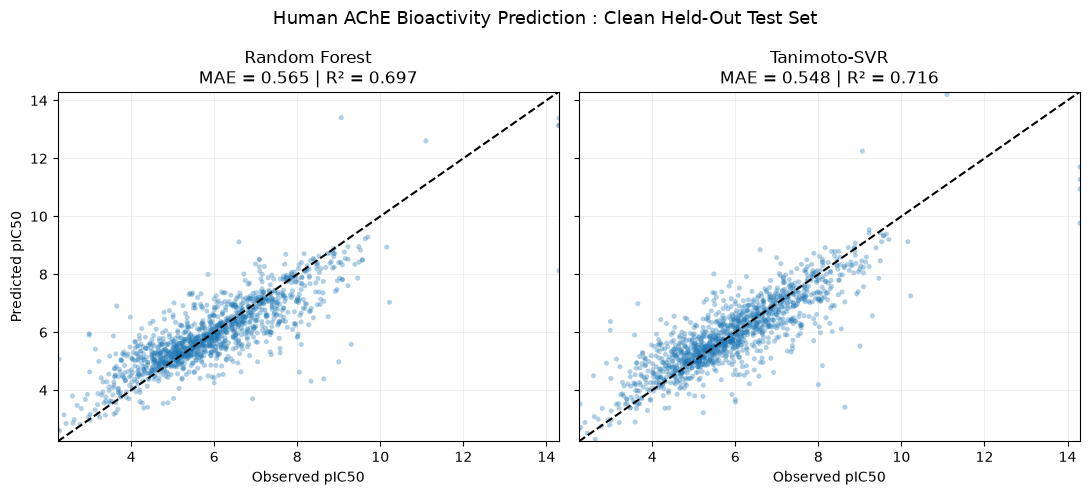

Saved: [local output path omitted]
Test molecules: 1256
Observed pIC50 range: 2.227898430722988 14.30102999566398
RF prediction range: 2.6039926801782154 13.403383357347437
SVR prediction range: 2.304487183909853 14.201014602771695


In [188]:
#Day 32:
#Predicted versus observed pIC50
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
from pathlib import Path

# Original frozen clean-test arrays
observed = np.asarray(y_test)
rf_pred = np.asarray(rf_test_pred)
svr_pred = np.asarray(svr_test_pred)

assert len(observed) == 1256
assert len(rf_pred) == len(observed)
assert len(svr_pred) == len(observed)

# Common axis limits for fair visual comparison
lower = min(observed.min(), rf_pred.min(), svr_pred.min())
upper = max(observed.max(), rf_pred.max(), svr_pred.max())

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5),
    sharex=True,
    sharey=True
)

models = [
    ("Random Forest", rf_pred),
    ("Tanimoto-SVR", svr_pred)
]

for ax, (name, predicted) in zip(axes, models):

    ax.scatter(
        observed,
        predicted,
        s=13,
        alpha=0.35,
        edgecolors="none"
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "k--",
        linewidth=1.5,
        label="Perfect prediction"
    )

    mae = mean_absolute_error(observed, predicted)
    r2 = r2_score(observed, predicted)

    ax.set_title(
        f"{name}\nMAE = {mae:.3f} | R² = {r2:.3f}"
    )

    ax.set_xlabel("Observed pIC50")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Predicted pIC50")

fig.suptitle(
    "Human AChE Bioactivity Prediction : Clean Held-Out Test Set",
    fontsize=13
)

fig.tight_layout()

output_dir = Path("results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "figure_01_predicted_vs_observed.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path.resolve())
print("Test molecules:", len(observed))
print("Observed pIC50 range:", observed.min(), observed.max())
print("RF prediction range:", rf_pred.min(), rf_pred.max())
print("SVR prediction range:", svr_pred.min(), svr_pred.max())

In [189]:
#Experiment 2: Quantify systematic prediction bias
import numpy as np
import pandas as pd

bias_df = pd.DataFrame({
    "observed": np.asarray(y_test),
    "rf_error": np.asarray(rf_test_pred) - np.asarray(y_test),
    "svr_error": np.asarray(svr_test_pred) - np.asarray(y_test),
})

bias_df["activity_quartile"] = pd.qcut(
    bias_df["observed"],
    q=4,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    duplicates="drop"
)

summary = bias_df.groupby(
    "activity_quartile",
    observed=True
).agg(
    n=("observed", "size"),
    min_pIC50=("observed", "min"),
    max_pIC50=("observed", "max"),
    rf_mean_error=("rf_error", "mean"),
    svr_mean_error=("svr_error", "mean"),
    rf_mae=("rf_error", lambda x: np.abs(x).mean()),
    svr_mae=("svr_error", lambda x: np.abs(x).mean()),
)

print(summary.round(3))

                     n  min_pIC50  max_pIC50  rf_mean_error  svr_mean_error  \
activity_quartile                                                             
Q1 (lowest)        314      2.228      4.963          0.560           0.476   
Q2                 314      4.965      5.854          0.154           0.149   
Q3                 314      5.863      6.876         -0.166          -0.135   
Q4 (highest)       314      6.883     14.301         -0.600          -0.471   

                   rf_mae  svr_mae  
activity_quartile                   
Q1 (lowest)         0.639    0.597  
Q2                  0.391    0.411  
Q3                  0.462    0.489  
Q4 (highest)        0.769    0.695  


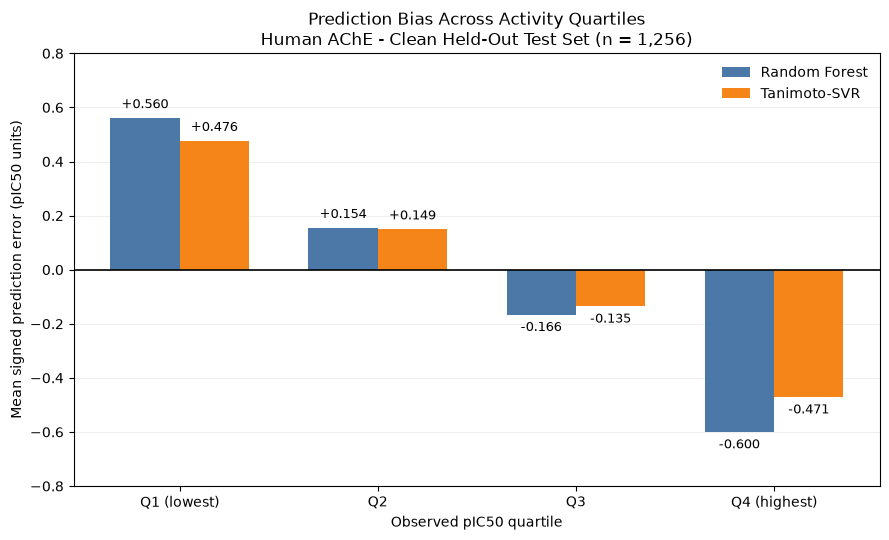

Saved: [local output path omitted]


In [191]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

quartiles = summary.index.astype(str).tolist()

rf_bias = summary["rf_mean_error"].to_numpy()
svr_bias = summary["svr_mean_error"].to_numpy()

x = np.arange(len(quartiles))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

bars_rf = ax.bar(
    x - width / 2,
    rf_bias,
    width,
    label="Random Forest",
    color="#4C78A8"
)

bars_svr = ax.bar(
    x + width / 2,
    svr_bias,
    width,
    label="Tanimoto-SVR",
    color="#F58518"
)

# Zero-error reference
ax.axhline(
    0,
    color="black",
    linewidth=1.2
)

# Numerical labels
for bars in [bars_rf, bars_svr]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:+.3f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 5 if height >= 0 else -5),
            textcoords="offset points",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(quartiles)

ax.set_ylabel(
    "Mean signed prediction error (pIC50 units)"
)
ax.set_xlabel("Observed pIC50 quartile")

ax.set_title(
    "Prediction Bias Across Activity Quartiles\n"
    "Human AChE - Clean Held-Out Test Set (n = 1,256)"
)

ax.set_ylim(-0.8, 0.8)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_dir = Path("results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "figure_02_signed_error_by_activity_quartile.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

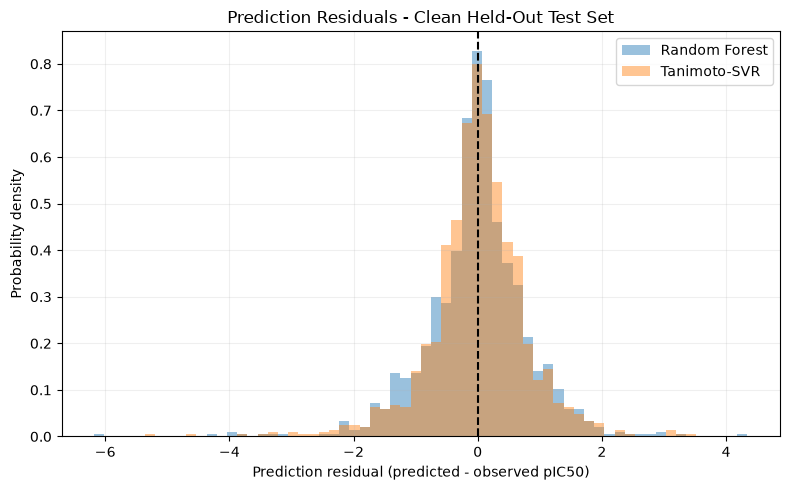

Saved: [local output path omitted]

Random Forest
Mean signed error: -0.0127
Median signed error: 0.0113
Residual standard deviation: 0.8154
Fraction |error| > 1: 0.1823
Fraction |error| > 2: 0.0239

Tanimoto-SVR
Mean signed error: 0.0049
Median signed error: 0.0199
Residual standard deviation: 0.7889
Fraction |error| > 1: 0.1497
Fraction |error| > 2: 0.0263


In [194]:
#Experiment 3: Residual distributions
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

rf_residuals = np.asarray(rf_test_pred) - np.asarray(y_test)
svr_residuals = np.asarray(svr_test_pred) - np.asarray(y_test)

fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(
    min(rf_residuals.min(), svr_residuals.min()),
    max(rf_residuals.max(), svr_residuals.max()),
    65
)

ax.hist(
    rf_residuals,
    bins=bins,
    density=True,
    alpha=0.45,
    label="Random Forest"
)

ax.hist(
    svr_residuals,
    bins=bins,
    density=True,
    alpha=0.45,
    label="Tanimoto-SVR"
)

ax.axvline(0, color="black", linestyle="--", linewidth=1.5)

ax.set_xlabel("Prediction residual (predicted - observed pIC50)")
ax.set_ylabel("Probability density")
ax.set_title("Prediction Residuals - Clean Held-Out Test Set")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

output_path = Path("results/figures/figure_02_residual_distributions.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path.resolve())

for name, residuals in [
    ("Random Forest", rf_residuals),
    ("Tanimoto-SVR", svr_residuals)
]:
    print(f"\n{name}")
    print("Mean signed error:", round(residuals.mean(), 4))
    print("Median signed error:", round(np.median(residuals), 4))
    print("Residual standard deviation:", round(residuals.std(), 4))
    print("Fraction |error| > 1:", round(np.mean(np.abs(residuals) > 1), 4))
    print("Fraction |error| > 2:", round(np.mean(np.abs(residuals) > 2), 4))

In [195]:
#Expeimport numpy as np

for name, predictions in [
    ("Random Forest", rf_test_pred),
    ("Tanimoto-SVR", svr_test_pred)
]:
    residuals = np.asarray(predictions) - np.asarray(y_test)

    print(f"\n{name}")
    print("Mean signed error:", round(residuals.mean(), 4))
    print("Median signed error:", round(np.median(residuals), 4))
    print("Residual standard deviation:", round(residuals.std(), 4))
    print("Fraction |error| > 1:", round(np.mean(np.abs(residuals) > 1), 4))
    print("Fraction |error| > 2:", round(np.mean(np.abs(residuals) > 2), 4))


Random Forest
Mean signed error: -0.0127
Median signed error: 0.0113
Residual standard deviation: 0.8154
Fraction |error| > 1: 0.1823
Fraction |error| > 2: 0.0239

Tanimoto-SVR
Mean signed error: 0.0049
Median signed error: 0.0199
Residual standard deviation: 0.7889
Fraction |error| > 1: 0.1497
Fraction |error| > 2: 0.0263


In [196]:
#Experiment 4: Applicability-domain coverage versus accuracy
import numpy as np
from rdkit import DataStructs
from sklearn.metrics import mean_absolute_error

# Frozen validation-derived thresholds
uncertainty_threshold = 0.7581355859721572
similarity_threshold = 0.7142857142857143

# Reconstruct RF tree disagreement on clean test molecules
tree_predictions = np.array([
    tree.predict(X_test)
    for tree in rf_reloaded.estimators_
])

test_uncertainty = tree_predictions.std(axis=0)

# K_test contains Tanimoto similarities to training molecules
test_similarity = K_test.max(axis=1)

inside_ad = (
    (test_uncertainty <= uncertainty_threshold)
    & (test_similarity >= similarity_threshold)
)

outside_ad = ~inside_ad

print("Clean test molecules:", len(y_test))
print("Inside AD:", inside_ad.sum())
print("Outside AD:", outside_ad.sum())
print("Coverage:", round(inside_ad.mean(), 4))

print(
    "RF MAE inside:",
    round(mean_absolute_error(
        np.asarray(y_test)[inside_ad],
        np.asarray(rf_test_pred)[inside_ad]
    ), 4)
)

print(
    "RF MAE outside:",
    round(mean_absolute_error(
        np.asarray(y_test)[outside_ad],
        np.asarray(rf_test_pred)[outside_ad]
    ), 4)
)

Clean test molecules: 1256
Inside AD: 636
Outside AD: 620
Coverage: 0.5064
RF MAE inside: 0.3956
RF MAE outside: 0.7397


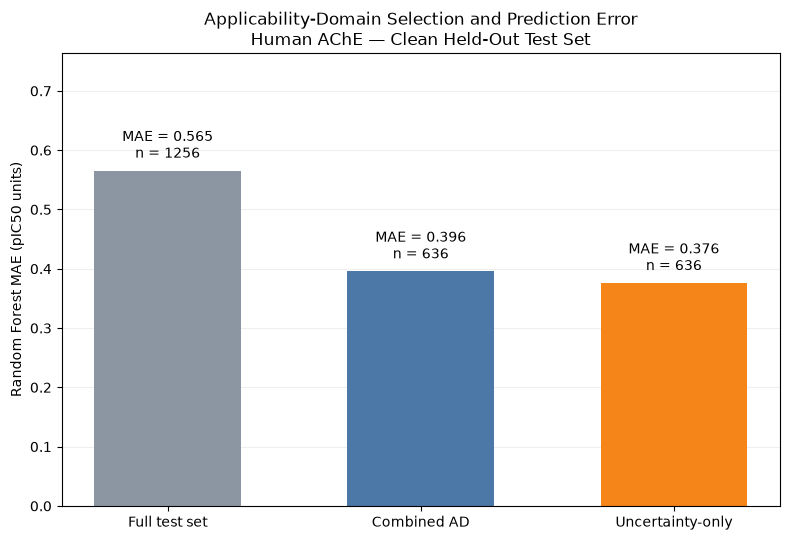

Saved: [local output path omitted]
Combined AD coverage: 0.5064
Uncertainty-only coverage: 0.5064
MAEs: [0.5654, 0.3956, 0.3758]


In [197]:
#Experiment 4B: Applicability-domain figure
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from pathlib import Path

observed = np.asarray(y_test)
predicted = np.asarray(rf_test_pred)

n_inside = int(inside_ad.sum())

# Select the same number of molecules by lowest RF disagreement.
# Stable sorting makes tie handling deterministic.
uncertainty_order = np.argsort(
    test_uncertainty,
    kind="stable"
)

uncertainty_only = np.zeros(len(observed), dtype=bool)
uncertainty_only[uncertainty_order[:n_inside]] = True

labels = [
    "Full test set",
    "Combined AD",
    "Uncertainty-only"
]

maes = [
    mean_absolute_error(observed, predicted),
    mean_absolute_error(
        observed[inside_ad],
        predicted[inside_ad]
    ),
    mean_absolute_error(
        observed[uncertainty_only],
        predicted[uncertainty_only]
    )
]

counts = [
    len(observed),
    int(inside_ad.sum()),
    int(uncertainty_only.sum())
]

fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.bar(
    labels,
    maes,
    color=["#8C96A3", "#4C78A8", "#F58518"],
    width=0.58
)

for bar, mae, n in zip(bars, maes, counts):
    ax.annotate(
        f"MAE = {mae:.3f}\nn = {n}",
        xy=(bar.get_x() + bar.get_width() / 2, mae),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylabel("Random Forest MAE (pIC50 units)")
ax.set_title(
    "Applicability-Domain Selection and Prediction Error\n"
    "Human AChE — Clean Held-Out Test Set"
)
ax.set_ylim(0, max(maes) * 1.35)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_path = Path(
    "results/figures/figure_04_applicability_domain_mae.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path.resolve())
print("Combined AD coverage:", round(inside_ad.mean(), 4))
print("Uncertainty-only coverage:", round(uncertainty_only.mean(), 4))
print("MAEs:", [round(value, 4) for value in maes])

In [198]:
#5A — Similarity versus absolute error
import numpy as np
import pandas as pd

similarity_df = pd.DataFrame({
    "nearest_train_similarity": test_similarity,
    "rf_abs_error": np.abs(
        np.asarray(rf_test_pred) - np.asarray(y_test)
    ),
    "svr_abs_error": np.abs(
        np.asarray(svr_test_pred) - np.asarray(y_test)
    )
})

similarity_df["similarity_quartile"] = pd.qcut(
    similarity_df["nearest_train_similarity"],
    q=4,
    labels=[
        "Q1 (least similar)",
        "Q2",
        "Q3",
        "Q4 (most similar)"
    ],
    duplicates="drop"
)

similarity_summary = similarity_df.groupby(
    "similarity_quartile",
    observed=True
).agg(
    n=("nearest_train_similarity", "size"),
    min_similarity=("nearest_train_similarity", "min"),
    max_similarity=("nearest_train_similarity", "max"),
    median_similarity=("nearest_train_similarity", "median"),
    rf_mae=("rf_abs_error", "mean"),
    svr_mae=("svr_abs_error", "mean")
)

print(similarity_summary.round(4))

                       n  min_similarity  max_similarity  median_similarity  \
similarity_quartile                                                           
Q1 (least similar)   314          0.1731          0.6792             0.5747   
Q2                   315          0.6800          0.7931             0.7500   
Q3                   313          0.7937          0.8833             0.8333   
Q4 (most similar)    314          0.8846          1.0000             0.9811   

                     rf_mae  svr_mae  
similarity_quartile                   
Q1 (least similar)   0.7542   0.7422  
Q2                   0.5289   0.5048  
Q3                   0.4505   0.4211  
Q4 (most similar)    0.5278   0.5235  


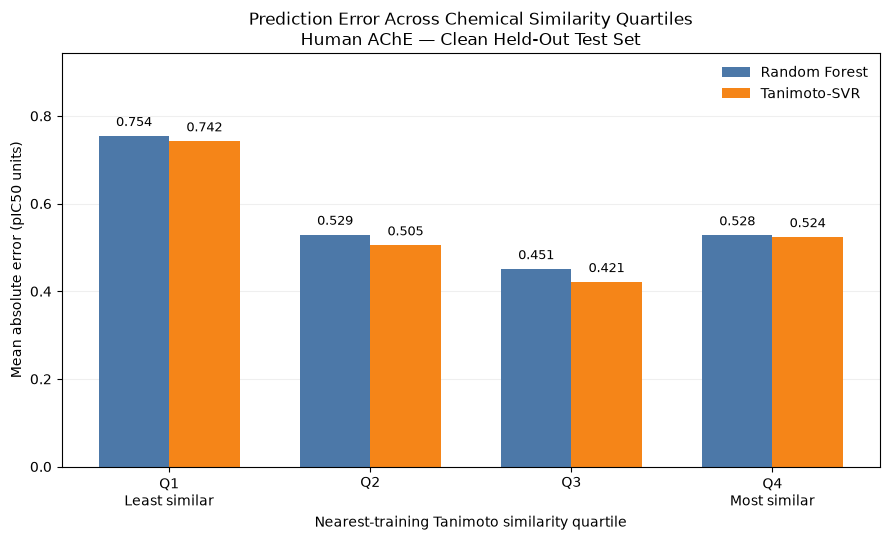

Saved: [local output path omitted]


In [199]:
#Experiment 5B: Save the similarity–error figure
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

labels = [
    "Q1\nLeast similar",
    "Q2",
    "Q3",
    "Q4\nMost similar"
]

rf_values = similarity_summary["rf_mae"].to_numpy()
svr_values = similarity_summary["svr_mae"].to_numpy()

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

rf_bars = ax.bar(
    x - width / 2,
    rf_values,
    width,
    label="Random Forest",
    color="#4C78A8"
)

svr_bars = ax.bar(
    x + width / 2,
    svr_values,
    width,
    label="Tanimoto-SVR",
    color="#F58518"
)

for bars in (rf_bars, svr_bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Nearest-training Tanimoto similarity quartile")
ax.set_ylabel("Mean absolute error (pIC50 units)")
ax.set_title(
    "Prediction Error Across Chemical Similarity Quartiles\n"
    "Human AChE — Clean Held-Out Test Set"
)

ax.set_ylim(0, max(rf_values.max(), svr_values.max()) * 1.25)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_path = Path(
    "results/figures/figure_05_similarity_vs_error.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path.resolve())

In [200]:
#Experiment 6: Scaffold generalization
import numpy as np
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import mean_absolute_error

def murcko_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

# Use the original training and clean-test index order
training_scaffolds = {
    murcko_scaffold(df.iloc[i]["canonical_smiles"])
    for i in gnn_train_idx
}

test_scaffolds = [
    murcko_scaffold(df.iloc[i]["canonical_smiles"])
    for i in test_indices
]

seen_scaffold = np.array([
    scaffold in training_scaffolds
    for scaffold in test_scaffolds
])

for label, mask in [
    ("Seen scaffold", seen_scaffold),
    ("Unseen scaffold", ~seen_scaffold)
]:
    print(f"\n{label}")
    print("Molecules:", mask.sum())
    print("Fraction:", round(mask.mean(), 4))

    print(
        "RF MAE:",
        round(mean_absolute_error(
            np.asarray(y_test)[mask],
            np.asarray(rf_test_pred)[mask]
        ), 4)
    )

    print(
        "SVR MAE:",
        round(mean_absolute_error(
            np.asarray(y_test)[mask],
            np.asarray(svr_test_pred)[mask]
        ), 4)
    )


Seen scaffold
Molecules: 736
Fraction: 0.586
RF MAE: 0.516
SVR MAE: 0.4971

Unseen scaffold
Molecules: 520
Fraction: 0.414
RF MAE: 0.6355
SVR MAE: 0.6199


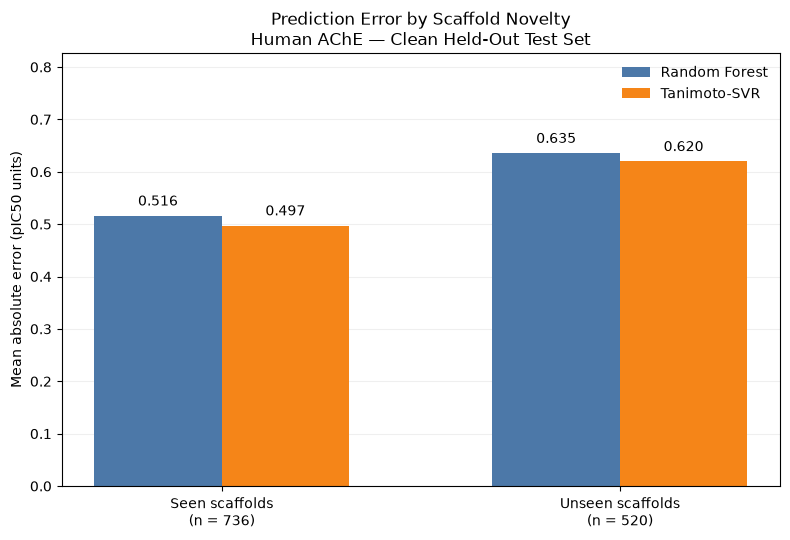

Saved: [local output path omitted]
Seen scaffold count: 736
Unseen scaffold count: 520
RF MAEs: [0.516, 0.6355]
SVR MAEs: [0.4971, 0.6199]


In [201]:
#Experiment 6B — Create the scaffold-generalization figure
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error

observed = np.asarray(y_test)
rf_predictions = np.asarray(rf_test_pred)
svr_predictions = np.asarray(svr_test_pred)

groups = [
    ("Seen scaffolds", seen_scaffold),
    ("Unseen scaffolds", ~seen_scaffold)
]

rf_maes = [
    mean_absolute_error(observed[mask], rf_predictions[mask])
    for _, mask in groups
]

svr_maes = [
    mean_absolute_error(observed[mask], svr_predictions[mask])
    for _, mask in groups
]

counts = [int(mask.sum()) for _, mask in groups]

x = np.arange(len(groups))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 5.5))

bars_rf = ax.bar(
    x - width / 2,
    rf_maes,
    width,
    label="Random Forest",
    color="#4C78A8"
)

bars_svr = ax.bar(
    x + width / 2,
    svr_maes,
    width,
    label="Tanimoto-SVR",
    color="#F58518"
)

for bars in (bars_rf, bars_svr):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10
        )

ax.set_xticks(x)
ax.set_xticklabels([
    f"{name}\n(n = {count})"
    for (name, _), count in zip(groups, counts)
])

ax.set_ylabel("Mean absolute error (pIC50 units)")
ax.set_title(
    "Prediction Error by Scaffold Novelty\n"
    "Human AChE — Clean Held-Out Test Set"
)

ax.set_ylim(0, max(rf_maes + svr_maes) * 1.3)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_path = Path(
    "results/figures/figure_06_scaffold_generalization.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())
print("Seen scaffold count:", counts[0])
print("Unseen scaffold count:", counts[1])
print("RF MAEs:", [round(x, 4) for x in rf_maes])
print("SVR MAEs:", [round(x, 4) for x in svr_maes])

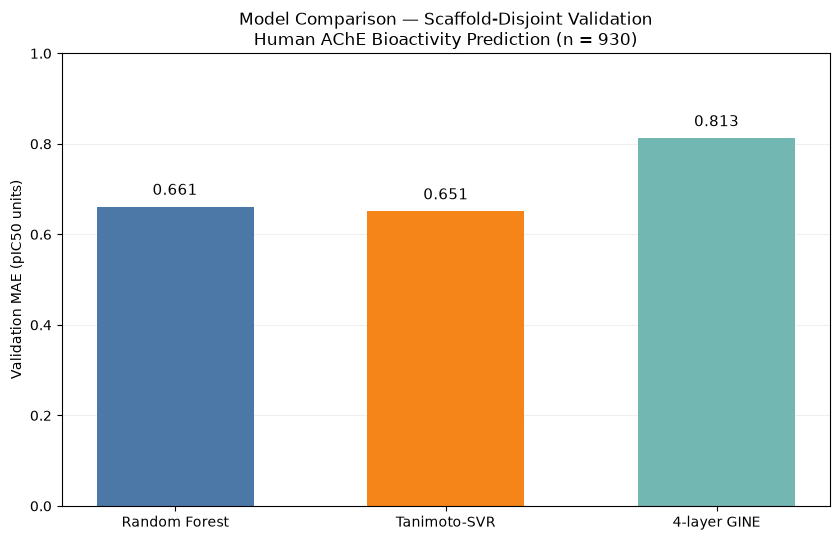

Saved: [local output path omitted]


In [202]:
#Day 32 — Experiment 7: Final model-comparison figure
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

models = [
    "Random Forest",
    "Tanimoto-SVR",
    "4-layer GINE"
]

validation_mae = np.array([
    0.661,
    0.651,
    0.812569
])

fig, ax = plt.subplots(figsize=(8.5, 5.5))

bars = ax.bar(
    models,
    validation_mae,
    color=["#4C78A8", "#F58518", "#72B7B2"],
    width=0.58
)

for bar, value in zip(bars, validation_mae):
    ax.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylabel("Validation MAE (pIC50 units)")
ax.set_title(
    "Model Comparison — Scaffold-Disjoint Validation\n"
    "Human AChE Bioactivity Prediction (n = 930)"
)

ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_path = Path(
    "results/figures/figure_07_validation_model_comparison.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

In [1]:
#Experiment 8: Final results table
import pandas as pd
from pathlib import Path

results = pd.DataFrame([
    {
        "model": "Random Forest",
        "representation": "Morgan count fingerprint, radius 2, 2048 features",
        "validation_mae": 0.661,
        "validation_rmse": 0.907,
        "validation_r2": 0.626,
        "test_mae": 0.565433,
        "test_rmse": 0.815533,
        "test_r2": 0.696993,
        "test_evaluated": True
    },
    {
        "model": "Tanimoto-SVR",
        "representation": "Morgan binary fingerprint, radius 2, 2048 bits",
        "validation_mae": 0.651,
        "validation_rmse": 0.889,
        "validation_r2": 0.642,
        "test_mae": 0.547969,
        "test_rmse": 0.788877,
        "test_r2": 0.716477,
        "test_evaluated": True
    },
    {
        "model": "4-layer GINE",
        "representation": "2D molecular graph, 34 atom and 7 bond features",
        "validation_mae": 0.812569,
        "validation_rmse": 1.057631,
        "validation_r2": 0.492385,
        "test_mae": float("nan"),
        "test_rmse": float("nan"),
        "test_r2": float("nan"),
        "test_evaluated": False
    }
])

output_path = Path("results/ache_final_model_metrics.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

results.to_csv(output_path, index=False)

print(results.to_string(index=False))
print("\nSaved:", output_path.resolve())

        model                                    representation  validation_mae  validation_rmse  validation_r2  test_mae  test_rmse  test_r2  test_evaluated
Random Forest Morgan count fingerprint, radius 2, 2048 features        0.661000         0.907000       0.626000  0.565433   0.815533 0.696993            True
 Tanimoto-SVR    Morgan binary fingerprint, radius 2, 2048 bits        0.651000         0.889000       0.642000  0.547969   0.788877 0.716477            True
 4-layer GINE   2D molecular graph, 34 atom and 7 bond features        0.812569         1.057631       0.492385       NaN        NaN      NaN           False

Saved: [local output path omitted]


In [2]:
#Day33
#Check what is in our project folder
from pathlib import Path

project = Path.cwd()

print("Current folder:", project)
print("\nProject files:\n")

for item in sorted(project.iterdir()):
    if item.name.startswith("."):
        continue

    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        size_kb = item.stat().st_size / 1024
        print(f"[FILE]   {item.name} ({size_kb:.1f} KB)")

print("\nSaved figures:\n")

figure_folder = project / "results" / "figures"

if figure_folder.exists():
    for figure in sorted(figure_folder.iterdir()):
        if figure.is_file():
            print(figure.name)
else:
    print("No figures folder found.")

Current folder: [local path omitted]

Project files:

[FILE]   16_GNN_understanding.ipynb (39.5 KB)
[FILE]   Figure-caption.txt (3.0 KB)
[FILE]   PyG_bioactivity_Prediction.ipynb (809.6 KB)
[FOLDER] __pycache__
[FILE]   ache_environment_versions.json (0.3 KB)
[FILE]   ache_evaluation_protocol.json (12.9 KB)
[FILE]   ache_frozen_splits.npz (14.9 KB)
[FILE]   ache_gine_4layer_frozen.pt (150.7 KB)
[FILE]   ache_gnn_4layer_best.pt (150.5 KB)
[FILE]   ache_gnn_features.py (2.6 KB)
[FILE]   ache_gnn_model.py (1.1 KB)
[FILE]   ache_ic50_clean.csv (532.1 KB)
[FILE]   ache_requirements_inference.txt (0.1 KB)
[FILE]   ache_rf_frozen.joblib (47420.9 KB)
[FILE]   ache_tanimoto_svr_frozen.joblib (68.3 KB)
[FILE]   day23_journa.md (27.5 KB)
[FOLDER] results

Saved figures:

figure_01_predicted_vs_observed.png
figure_02_signed_error_by_activity_quartile.png
figure_03_residual_distributions.png
figure_04_applicability_domain_mae.png
figure_05_similarity_vs_error.png
figure_06_scaffold_generalization.p

In [3]:
#from pathlib import Path

project_root = Path.cwd().parent / "ache-bioactivity-ml"

folders = [
    "data",
    "models",
    "src",
    "configs",
    "notebooks",
    "results/figures",
    "reports",
    "environment",
]

for folder in folders:
    (project_root / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project folder:", project_root)
print("\nCreated folders:")

for folder in folders:
    print(" -", folder)

print("\nOriginal research folder unchanged:", Path.cwd())
from pathlib import Path

project_root = Path.cwd().parent / "ache-bioactivity-ml"

folders = [
    "data",
    "models",
    "src",
    "configs",
    "notebooks",
    "results/figures",
    "reports",
    "environment",
]

for folder in folders:
    (project_root / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project folder:", project_root)
print("\nCreated folders:")

for folder in folders:
    print(" -", folder)

print("\nOriginal research folder unchanged:", Path.cwd())

Project folder: ache-bioactivity-ml

Created folders:
 - data
 - models
 - src
 - configs
 - notebooks
 - results/figures
 - reports
 - environment

Original research folder unchanged.
Project folder: ache-bioactivity-ml

Created folders:
 - data
 - models
 - src
 - configs
 - notebooks
 - results/figures
 - reports
 - environment

Original research folder unchanged.
